# Phishing URL Detection: EDA, Feature Engineering and Model


In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 80)
sns.set_theme(style="whitegrid")

FIG = Path("figures") / "eda"
FIG.mkdir(parents=True, exist_ok=True)
for old in FIG.glob("*.png"):   # start fresh so old figures don't pile up
    old.unlink()

# blue = legitimate, orange = phishing (same in every plot)
PAL = {"Legitimate": "#2a78d6", "Phishing": "#eb6834"}
ORDER = ["Legitimate", "Phishing"]
SEED = 42

fig_no = 0
def save(name):
    """Number the current figure, save it to figures/eda/ and show it."""
    global fig_no
    fig_no += 1
    plt.tight_layout()
    plt.savefig(FIG / f"fig{fig_no:02d}_{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 1. Dataset & problem definition

**Dataset:** PhiUSIIL Phishing URL Dataset
**Source:**  https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset
**What it is:** about 235k website links, each marked as phishing or legitimate. For each link there are
54 columns, some about the link itself (length, digits, TLD...) and some about the page it opens

**Why I picked it:** I wanted to see what actually makes a
phishing link different from a real one.

**What I want to find out**
- Is the data balanced?
- Do phishing links look different (longer, more subdomains, no HTTPS)?
- Do phishing pages look different (smaller, fewer images and links, password fields)?
- Which endings like .com, .xyz, .top are used most by phishing sites?
- Which columns are most related to phishing, and are any of them "too good to be true"?

**What I expect:** phishing pages will be smaller, with fewer things like a logo,
description or copyright.

## 2. Data loading & structure

In [2]:
df = pd.read_csv("PhiUSIIL_Phishing_URL_Dataset.csv")
df.head()

,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,LineOfCode,LargestLineLength,HasTitle,Title,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,Robots,IsResponsive,NoOfURLRedirect,NoOfSelfRedirect,HasDescription,NoOfPopup,NoOfiFrame,HasExternalFormSubmit,HasSocialNet,HasSubmitButton,HasHiddenFields,HasPasswordField,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,0.061933,3,1,0,0,0.0,18,0.581,0,0.0,0,0,0,1,0.032,1,558,9381,1,à¸‚à¹ˆà¸²à¸§à¸ªà¸” à¸‚à¹ˆà¸²à¸§à¸§à¸±à¸™à¸™à¸µ...,0.000000,0.000000,0,1,1,0,0,0,0,1,0,0,1,1,0,1,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,0.050207,2,1,0,0,0.0,9,0.391,0,0.0,0,0,0,2,0.087,1,618,9381,1,johannes gutenberg-universitÃ¤t mainz,55.555556,55.555556,1,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,0.064129,2,2,0,0,0.0,15,0.517,0,0.0,0,0,0,2,0.069,1,467,682,1,voice fm southampton,46.666667,46.666667,0,1,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,0.057606,3,1,0,0,0.0,13,0.500,0,0.0,0,0,0,1,0.038,1,6356,26824,1,home page: seminars in fetal and neonatal medi...,0.000000,0.000000,0,1,1,0,0,0,1,12,0,1,1,1,0,0,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,0.059441,3,1,0,0,0.0,20,0.606,0,0.0,0,0,0,1,0.030,1,6089,28404,1,fundaciÃ³n rewilding argentina,100.000000,100.000000,0,1,1,1,1,1,0,2,0,1,1,1,0,1,1,0,1,244,15,34,72,1,85,1


In [3]:
print("Shape:", df.shape)

Shape: (235795, 56)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  str    
 1   URL                         235795 non-null  str    
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  str    
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  str    
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64  
 12  NoOfSubDomain               235795 non-null  int64  
 13  HasObfuscation           

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
URLLength,235795.0,34.573095,41.314153,13.000000,23.000000,27.000000,34.000000,6.097000e+03
DomainLength,235795.0,21.470396,9.150793,4.000000,16.000000,20.000000,24.000000,1.100000e+02
IsDomainIP,235795.0,0.002706,0.051946,0.000000,0.000000,0.000000,0.000000,1.000000e+00
URLSimilarityIndex,235795.0,78.430778,28.976055,0.155574,57.024793,100.000000,100.000000,1.000000e+02
CharContinuationRate,235795.0,0.845508,0.216632,0.000000,0.680000,1.000000,1.000000,1.000000e+00
TLDLegitimateProb,235795.0,0.260423,0.251628,0.000000,0.005977,0.079963,0.522907,5.229071e-01
URLCharProb,235795.0,0.055747,0.010587,0.001083,0.050747,0.057970,0.062875,9.082366e-02
TLDLength,235795.0,2.764456,0.599739,2.000000,2.000000,3.000000,3.000000,1.300000e+01
NoOfSubDomain,235795.0,1.164758,0.600969,0.000000,1.000000,1.000000,1.000000,1.000000e+01
HasObfuscation,235795.0,0.002057,0.045306,0.000000,0.000000,0.000000,0.000000,1.000000e+00


In [6]:
missing = df.isnull().sum()
print("Total missing values:", missing.sum())
missing

Total missing values: 0


FILENAME                      0
URL                           0
URLLength                     0
Domain                        0
DomainLength                  0
IsDomainIP                    0
TLD                           0
URLSimilarityIndex            0
CharContinuationRate          0
TLDLegitimateProb             0
URLCharProb                   0
TLDLength                     0
NoOfSubDomain                 0
HasObfuscation                0
NoOfObfuscatedChar            0
ObfuscationRatio              0
NoOfLettersInURL              0
LetterRatioInURL              0
NoOfDegitsInURL               0
DegitRatioInURL               0
NoOfEqualsInURL               0
NoOfQMarkInURL                0
NoOfAmpersandInURL            0
NoOfOtherSpecialCharsInURL    0
SpacialCharRatioInURL         0
IsHTTPS                       0
LineOfCode                    0
LargestLineLength             0
HasTitle                      0
Title                         0
DomainTitleMatchScore         0
URLTitle

In [7]:
# number of different values in each column (shows which ones are 0/1, categories or real numbers)
df.nunique().sort_values()

IsDomainIP                         2
HasObfuscation                     2
IsHTTPS                            2
HasTitle                           2
HasHiddenFields                    2
HasSubmitButton                    2
Bank                               2
HasPasswordField                   2
HasExternalFormSubmit              2
HasSocialNet                       2
HasDescription                     2
NoOfSelfRedirect                   2
NoOfURLRedirect                    2
IsResponsive                       2
Robots                             2
HasFavicon                         2
HasCopyrightInfo                   2
label                              2
Crypto                             2
Pay                                2
NoOfQMarkInURL                     5
NoOfSubDomain                     10
TLDLength                         12
NoOfObfuscatedChar                20
NoOfEqualsInURL                   25
NoOfAmpersandInURL                31
NoOfOtherSpecialCharsInURL        74
D

In [8]:
# label: 1 = legitimate, 0 = phishing
df["label"].value_counts()

label
1    134850
0    100945
Name: count, dtype: int64

**What I noticed**
- 235,795 rows and 56 columns. 5 are text (`FILENAME`, `URL`, `Domain`, `TLD`, `Title`), the rest are numbers.
- No missing values at all.
- A lot of columns are just 0/1 (yes/no), like `IsHTTPS` and `HasFavicon`.
- `label = 1` means **legitimate**, which is confusing, so I'll make an `is_phishing` column instead.
- Some column names are misspelled (`NoOfDegitsInURL`, `SpacialCharRatioInURL`).

## 3. Data cleaning

In [9]:
clean = df.copy()

# 1) missing values: none, so nothing to fill
print("Missing values:", clean.isnull().sum().sum())

# 2) duplicates
print("Exact duplicate rows:", clean.duplicated().sum())
print("Repeated URLs       :", clean["URL"].duplicated().sum())
clean = clean.drop_duplicates(subset="URL").reset_index(drop=True)
print("Rows after removing repeated URLs:", len(clean))

Missing values: 0


Exact duplicate rows: 0
Repeated URLs       : 425
Rows after removing repeated URLs: 235370


In [ ]:
# drop FILENAME (just a file id) and Title (free text in many languages, lots of broken characters)
clean = clean.drop(columns=["FILENAME", "Title"])

# fix the typos in column names
clean = clean.rename(columns={
    "NoOfDegitsInURL": "NoOfDigitsInURL",
    "DegitRatioInURL": "DigitRatioInURL",
    "SpacialCharRatioInURL": "SpecialCharRatioInURL",
})

# target: 1 = phishing, plus a readable name for the plots
clean["is_phishing"] = 1 - clean["label"]
clean["label_name"] = clean["is_phishing"].map({0: "Legitimate", 1: "Phishing"})
clean = clean.drop(columns=["label"])

# data types: lower-case TLD, 0/1 columns as small integers, class name as category
clean["TLD"] = clean["TLD"].str.lower()
binary_cols = [c for c in clean.select_dtypes("number").columns if clean[c].nunique() == 2]
clean[binary_cols] = clean[binary_cols].astype("int8")
clean["label_name"] = clean["label_name"].astype("category")

print("Binary columns:", len(binary_cols))
print("Shape after cleaning:", clean.shape)

Binary columns: 20
Shape after cleaning: (235370, 55)


## 4. Feature engineering


| New column | What it is | Why I need it |
|---|---|---|
| `has_www` | link has `www.` | to check the "every real link looks the same" problem (section 7). **Not for the model.** |
| `has_path` | link has something after the domain, like `/login` | same as above. **Not for the model.** |
| `domain_length` | length of the domain **without** `www.` | clean version of `DomainLength`/`URLLength` (those leak, see section 7) |
| `domain_digits` | digits in the domain | clean version of `NoOfDigitsInURL`, catches names like `amaz0n` |
| `domain_hyphens` | dashes in the domain | catches names like `paypal-secure-login.com` |
| `domain_dots` | dots in the domain | clean version of `NoOfSubDomain` (that one counts `www` too) |
| `trust_score` (0–7) | how many of: title, logo, description, social links, copyright, mobile-friendly, robots.txt | sums up "does this look like a real site" in one number, great for plots and the dashboard |
| `tld_group` | top 10 endings, the rest = "other" | only for plots |
| `page_size_group` | page size (lines of code) in 4 groups | only for plots |

In [11]:
url_no_scheme = clean["URL"].str.replace(r"^https?://", "", regex=True)
domain = clean["Domain"].str.lower().str.replace(r"^www\.", "", regex=True)

# only to check the leakage problem
clean["has_www"] = clean["URL"].str.contains("://www.", regex=False).astype("int8")
clean["has_path"] = url_no_scheme.str.contains("/").astype("int8")

# domain features, measured WITHOUT "www." so they don't depend on how the link was written
clean["domain_length"] = domain.str.len()
clean["domain_digits"] = domain.str.count(r"\d")
clean["domain_hyphens"] = domain.str.count("-")
clean["domain_dots"] = domain.str.count(r"\.")

# trust signals added up
clean["trust_score"] = clean[["HasTitle", "HasFavicon", "HasDescription", "HasSocialNet",
                              "HasCopyrightInfo", "IsResponsive", "Robots"]].sum(axis=1)

# groups for plots
top_tlds = clean["TLD"].value_counts().head(10).index
clean["tld_group"] = clean["TLD"].where(clean["TLD"].isin(top_tlds), "other")
clean["page_size_group"] = pd.cut(clean["LineOfCode"], bins=[-1, 50, 500, 2000, np.inf],
                                  labels=["tiny (<50)", "small (50-500)", "medium (500-2k)", "large (>2k)"])

NEW_FEATURES = ["has_www", "has_path", "domain_length", "domain_digits", "domain_hyphens", "domain_dots", "trust_score"]
clean[NEW_FEATURES + ["tld_group", "page_size_group"]].head()

,has_www,has_path,domain_length,domain_digits,domain_hyphens,domain_dots,trust_score,tld_group,page_size_group
0,1,0,20,0,0,1,4,com,medium (500-2k)
1,1,0,12,0,1,1,5,de,medium (500-2k)
2,1,0,18,0,0,2,5,uk,small (50-500)
3,1,0,15,0,0,1,5,com,large (>2k)
4,1,0,22,0,0,1,6,org,large (>2k)


In [12]:
clean[NEW_FEATURES].describe().T

,count,mean,std,min,25%,50%,75%,max
has_www,235370.0,0.750244,0.432872,0.0,1.0,1.0,1.0,1.0
has_path,235370.0,0.254948,0.435833,0.0,0.0,0.0,1.0,1.0
domain_length,235370.0,18.455300,9.844462,4.0,12.0,16.0,21.0,110.0
domain_digits,235370.0,0.878451,2.785269,0.0,0.0,0.0,0.0,67.0
domain_hyphens,235370.0,0.281009,0.750962,0.0,0.0,0.0,0.0,26.0
domain_dots,235370.0,1.414777,0.677579,1.0,1.0,1.0,2.0,11.0
trust_score,235370.0,3.501143,2.273480,0.0,1.0,4.0,6.0,7.0


In [13]:
clean.to_csv("clean_features.csv", index=False)
print("Saved clean_features.csv:", clean.shape)

Saved clean_features.csv: (235370, 64)


## 5. EDA – univariate analysis

### 5.1 Target

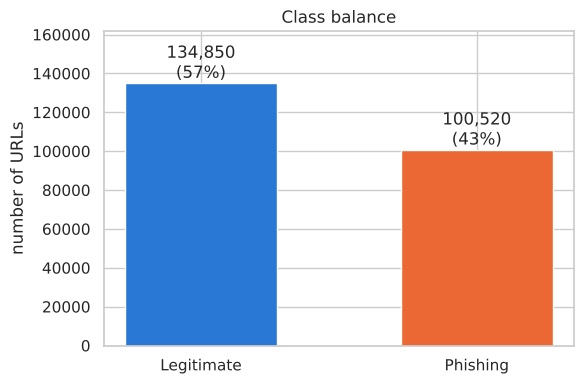

In [15]:
counts = clean["label_name"].value_counts().reindex(ORDER)
plt.figure(figsize=(6, 4))
bars = plt.bar(counts.index, counts.values, color=[PAL[k] for k in ORDER], width=0.55)
for b, v in zip(bars, counts.values):
    plt.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v / len(clean):.0%})", ha="center", va="bottom")
plt.ylim(0, counts.max() * 1.2)
plt.title("Class balance")
plt.ylabel("number of URLs")
save("class_balance")

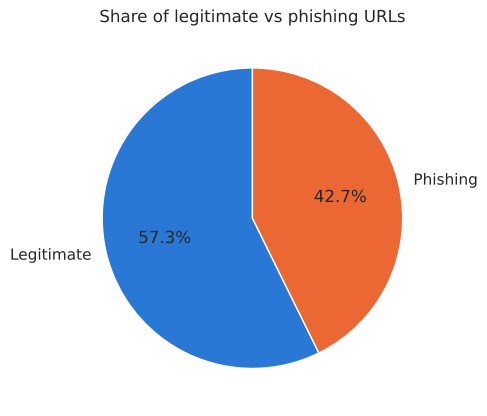

In [16]:
plt.figure(figsize=(5, 5))
plt.pie(counts.values, labels=counts.index, colors=[PAL[k] for k in ORDER], autopct="%1.1f%%",
        startangle=90, wedgeprops={"edgecolor": "white"})
plt.title("Share of legitimate vs phishing URLs")
save("class_pie")

### 5.2 Histograms

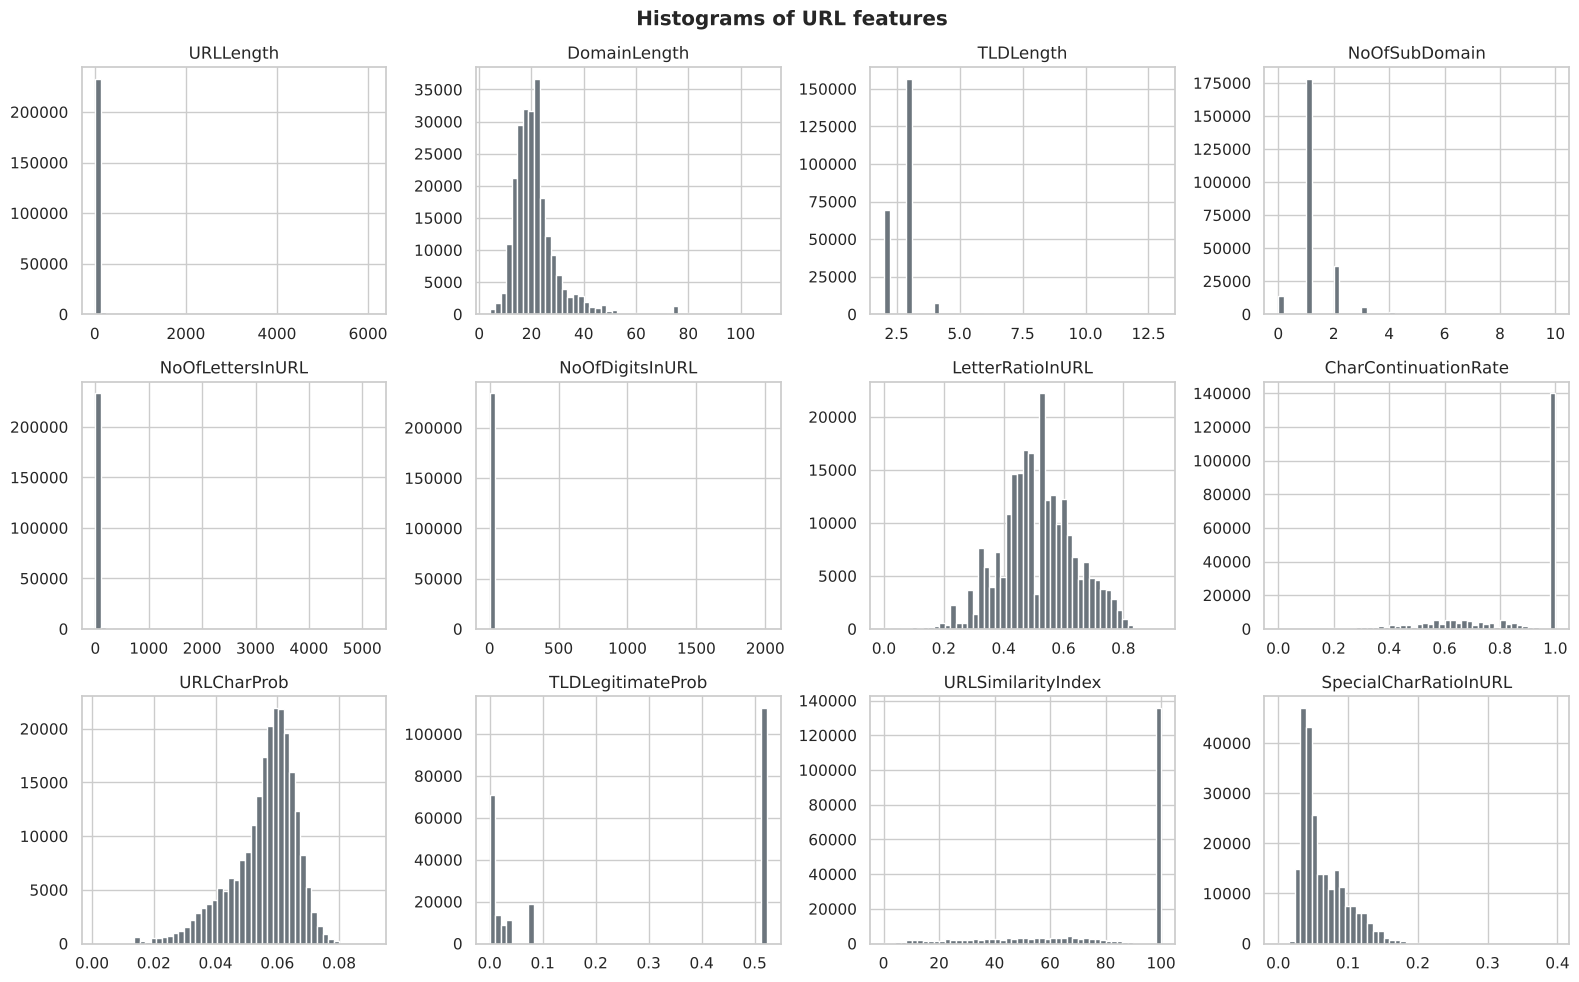

In [17]:
hist_cols = ["URLLength", "DomainLength", "TLDLength", "NoOfSubDomain", "NoOfLettersInURL", "NoOfDigitsInURL",
             "LetterRatioInURL", "CharContinuationRate", "URLCharProb", "TLDLegitimateProb",
             "URLSimilarityIndex", "SpecialCharRatioInURL"]
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, c in zip(axes.flat, hist_cols):
    ax.hist(clean[c], bins=50, color="#6c757d")
    ax.set_title(c)
plt.suptitle("Histograms of URL features", fontweight="bold")
save("hist_url_features")

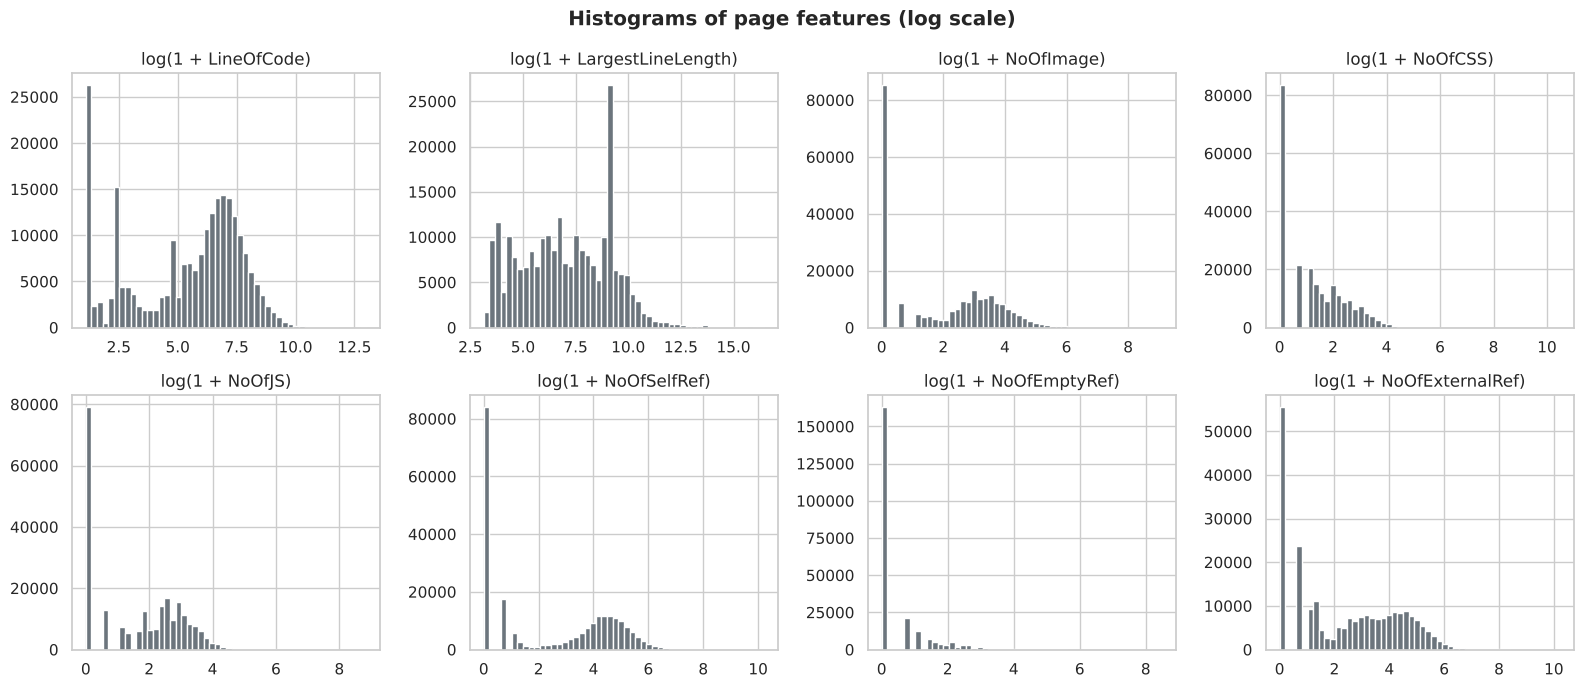

In [ ]:
# page counts are very skewed, so plot log(1 + x) was used
page_counts = ["LineOfCode", "LargestLineLength", "NoOfImage", "NoOfCSS", "NoOfJS",
               "NoOfSelfRef", "NoOfEmptyRef", "NoOfExternalRef"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.flat, page_counts):
    ax.hist(np.log1p(clean[c]), bins=50, color="#6c757d")
    ax.set_title(f"log(1 + {c})")
plt.suptitle("Histograms of page features (log scale)", fontweight="bold")
save("hist_page_features")

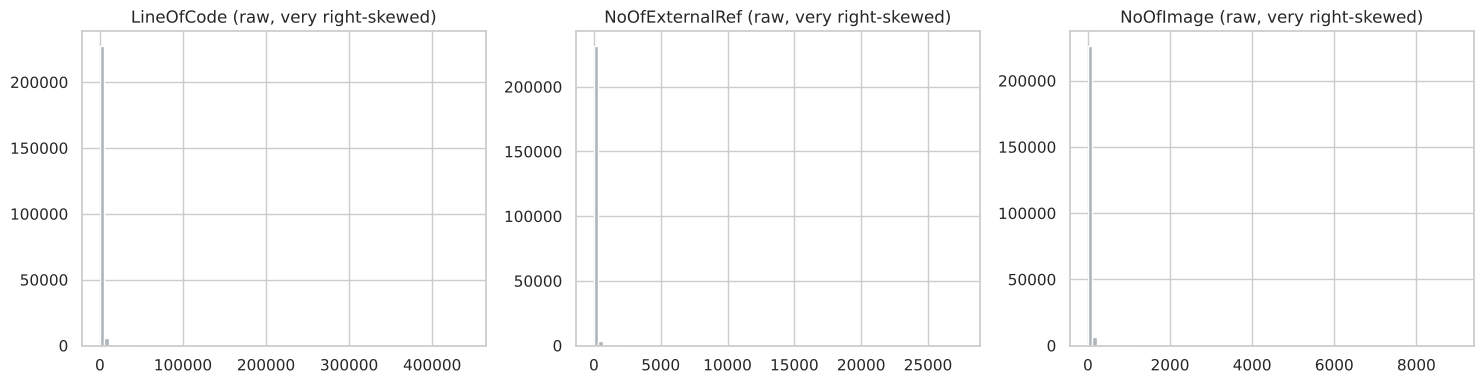

In [19]:
# the same counts WITHOUT the log, to show why the log is needed
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ["LineOfCode", "NoOfExternalRef", "NoOfImage"]):
    ax.hist(clean[c], bins=80, color="#adb5bd")
    ax.set_title(f"{c} (raw, very right-skewed)")
save("hist_raw_skewed")

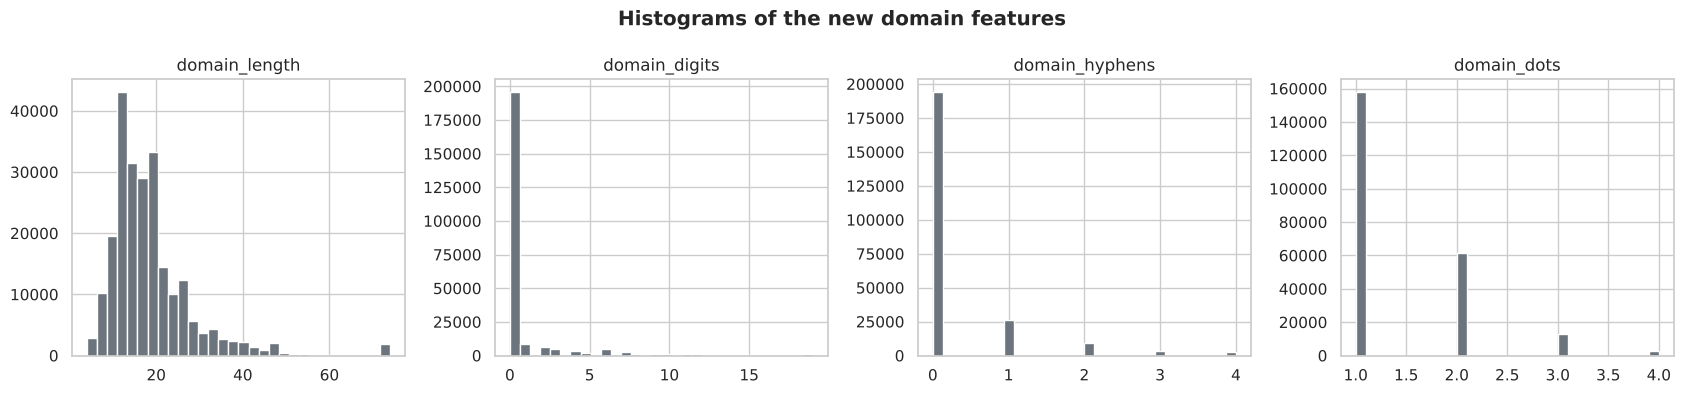

In [20]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, c in zip(axes, ["domain_length", "domain_digits", "domain_hyphens", "domain_dots"]):
    ax.hist(clean[c].clip(upper=clean[c].quantile(0.995)), bins=30, color="#6c757d")
    ax.set_title(c)
plt.suptitle("Histograms of the new domain features", fontweight="bold")
save("hist_domain_features")

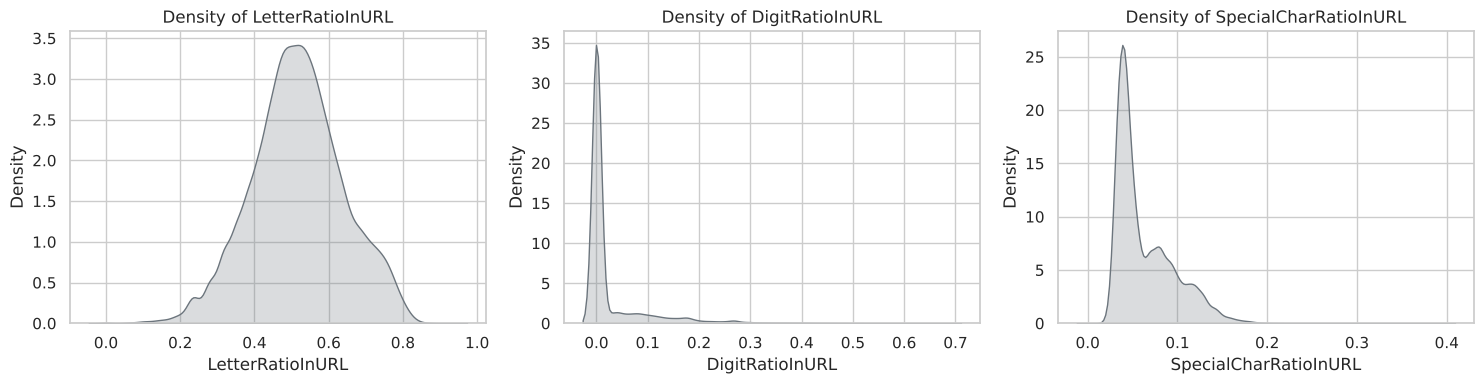

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ["LetterRatioInURL", "DigitRatioInURL", "SpecialCharRatioInURL"]):
    sns.kdeplot(clean[c], fill=True, ax=ax, color="#6c757d", bw_adjust=1.5)
    ax.set_title(f"Density of {c}")
save("kde_ratios")

### 5.3 Countplots

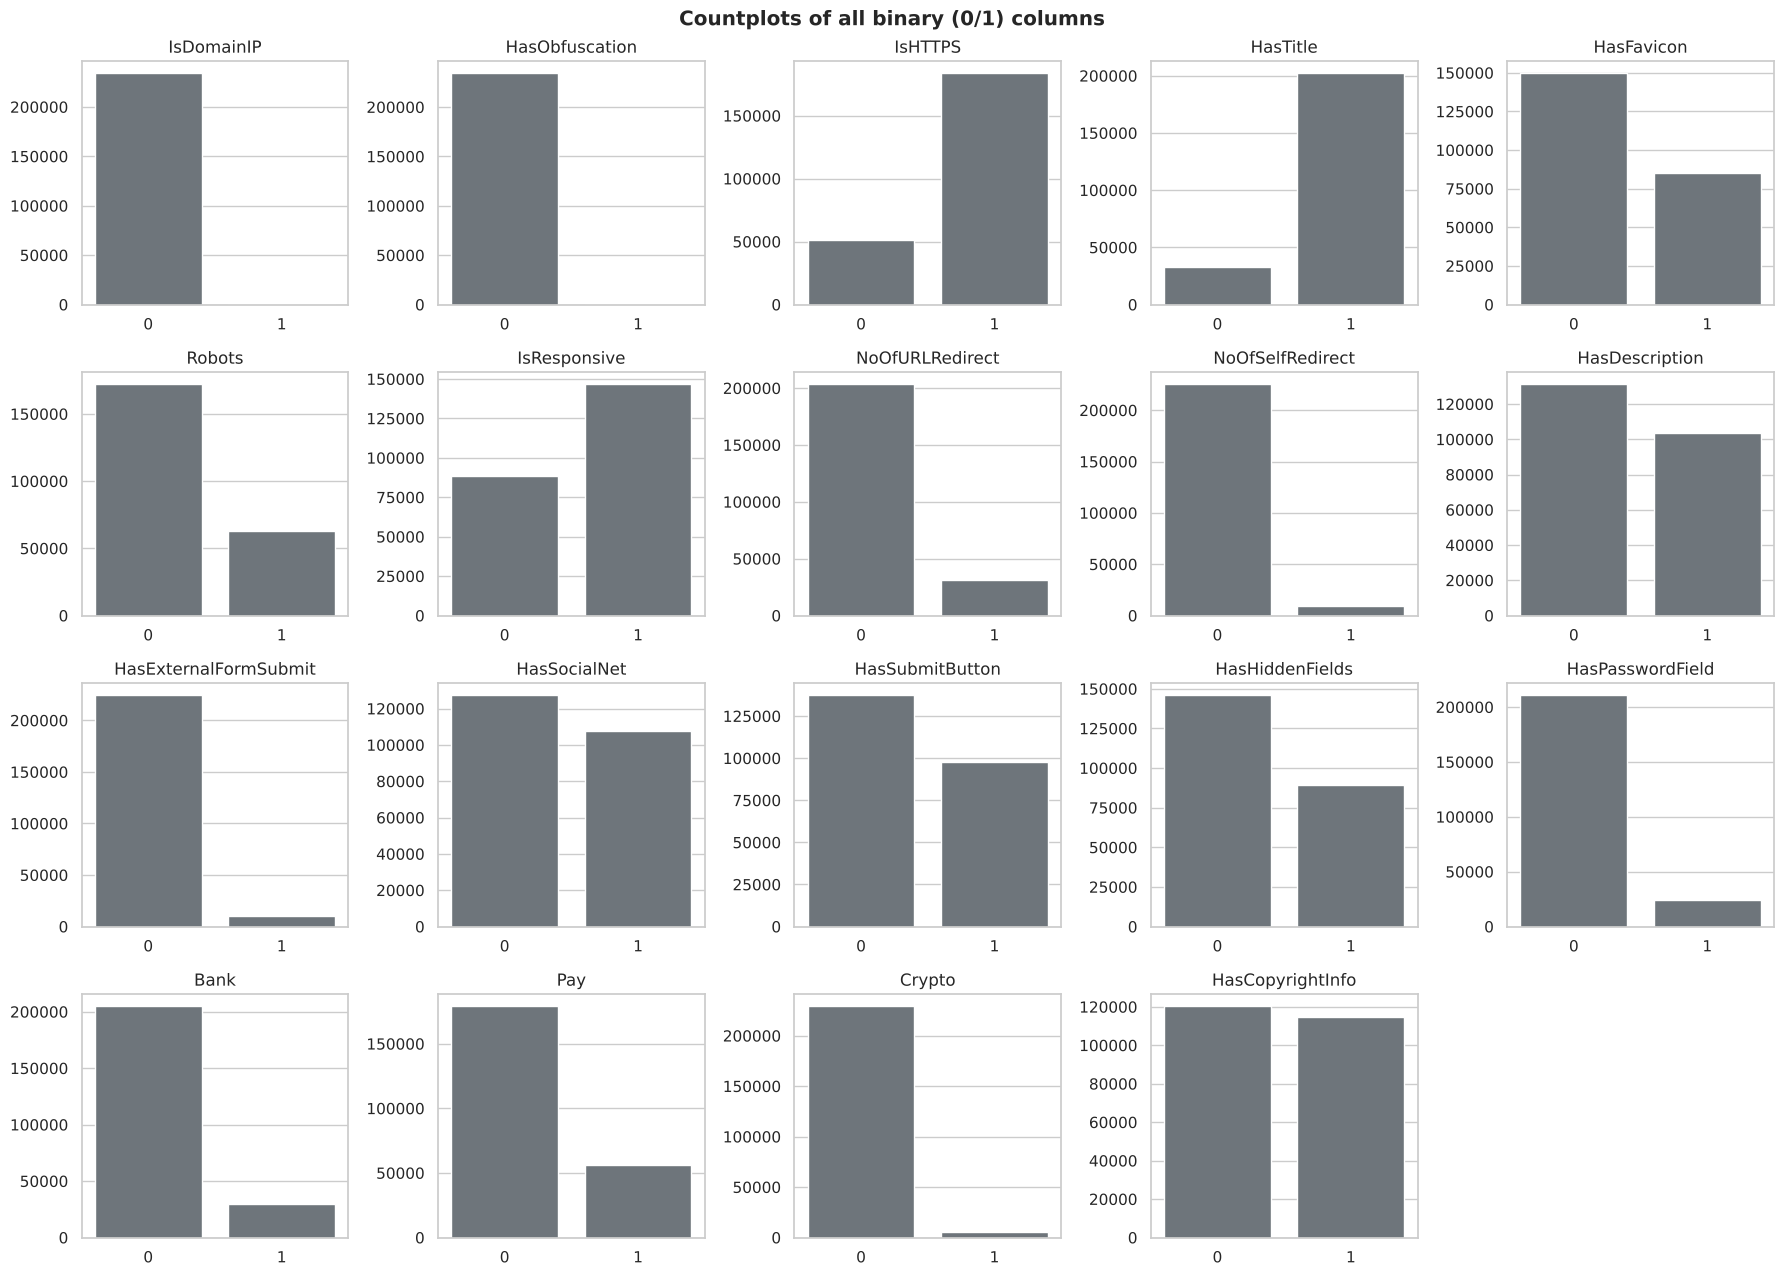

In [22]:
bin_plot_cols = [c for c in binary_cols if c != "is_phishing"]
fig, axes = plt.subplots(4, 5, figsize=(18, 13))
for ax, c in zip(axes.flat, bin_plot_cols):
    sns.countplot(x=clean[c], ax=ax, color="#6c757d")
    ax.set_title(c); ax.set_xlabel(""); ax.set_ylabel("")
for ax in axes.flat[len(bin_plot_cols):]:
    ax.axis("off")
plt.suptitle("Countplots of all binary (0/1) columns", fontweight="bold")
save("count_binary")

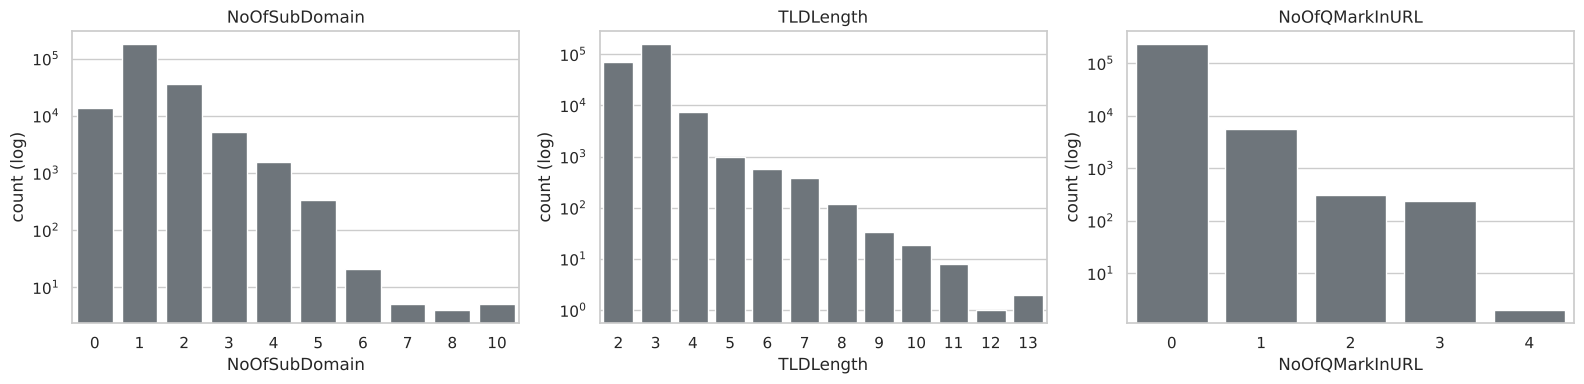

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, ["NoOfSubDomain", "TLDLength", "NoOfQMarkInURL"]):
    sns.countplot(x=clean[c], ax=ax, color="#6c757d")
    ax.set_title(c); ax.set_yscale("log"); ax.set_ylabel("count (log)")
save("count_small_ints")

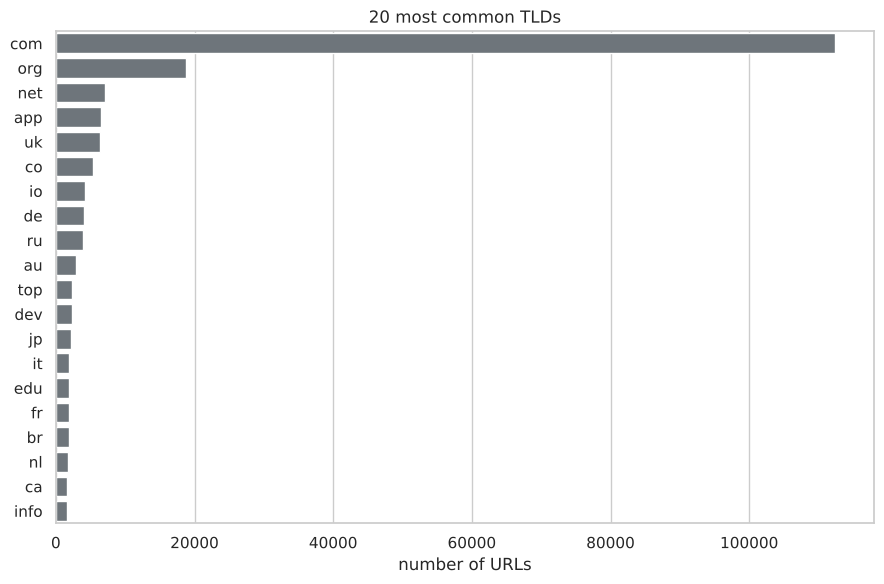

In [24]:
top20 = clean["TLD"].value_counts().head(20)
plt.figure(figsize=(9, 6))
sns.barplot(x=top20.values, y=top20.index, color="#6c757d")
plt.title("20 most common TLDs"); plt.xlabel("number of URLs"); plt.ylabel("")
save("count_top_tlds")

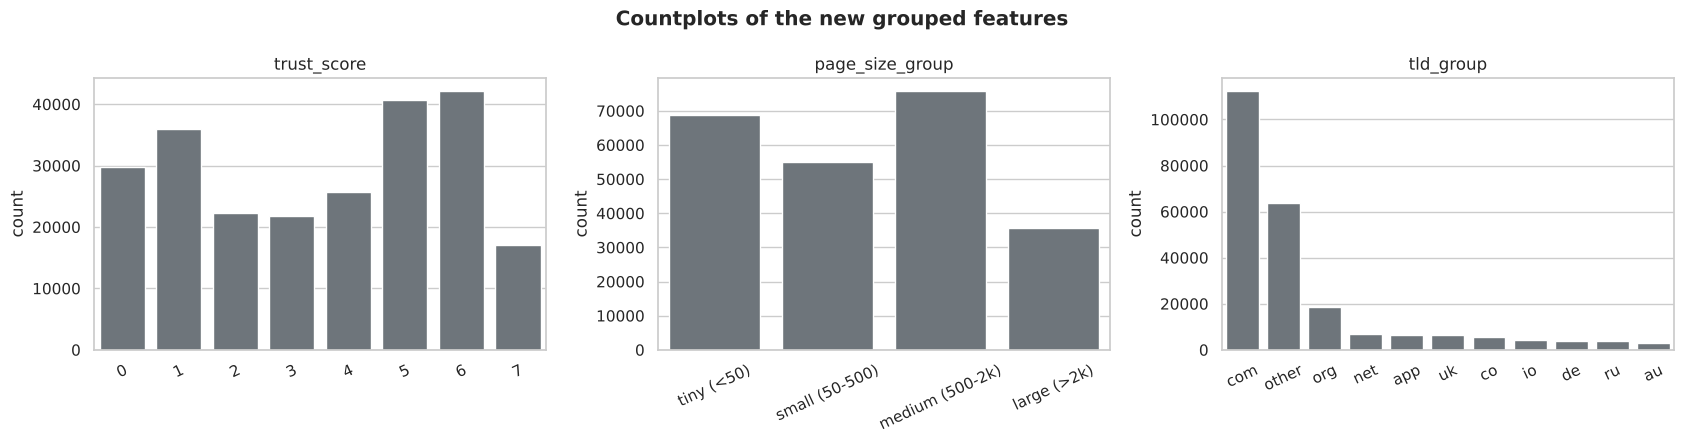

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, c in zip(axes, ["trust_score", "page_size_group", "tld_group"]):
    order = clean[c].value_counts().index if c == "tld_group" else None
    sns.countplot(x=clean[c], ax=ax, color="#6c757d", order=order)
    ax.set_title(c); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=25)
plt.suptitle("Countplots of the new grouped features", fontweight="bold")
save("count_engineered")

### 5.4 Boxplots

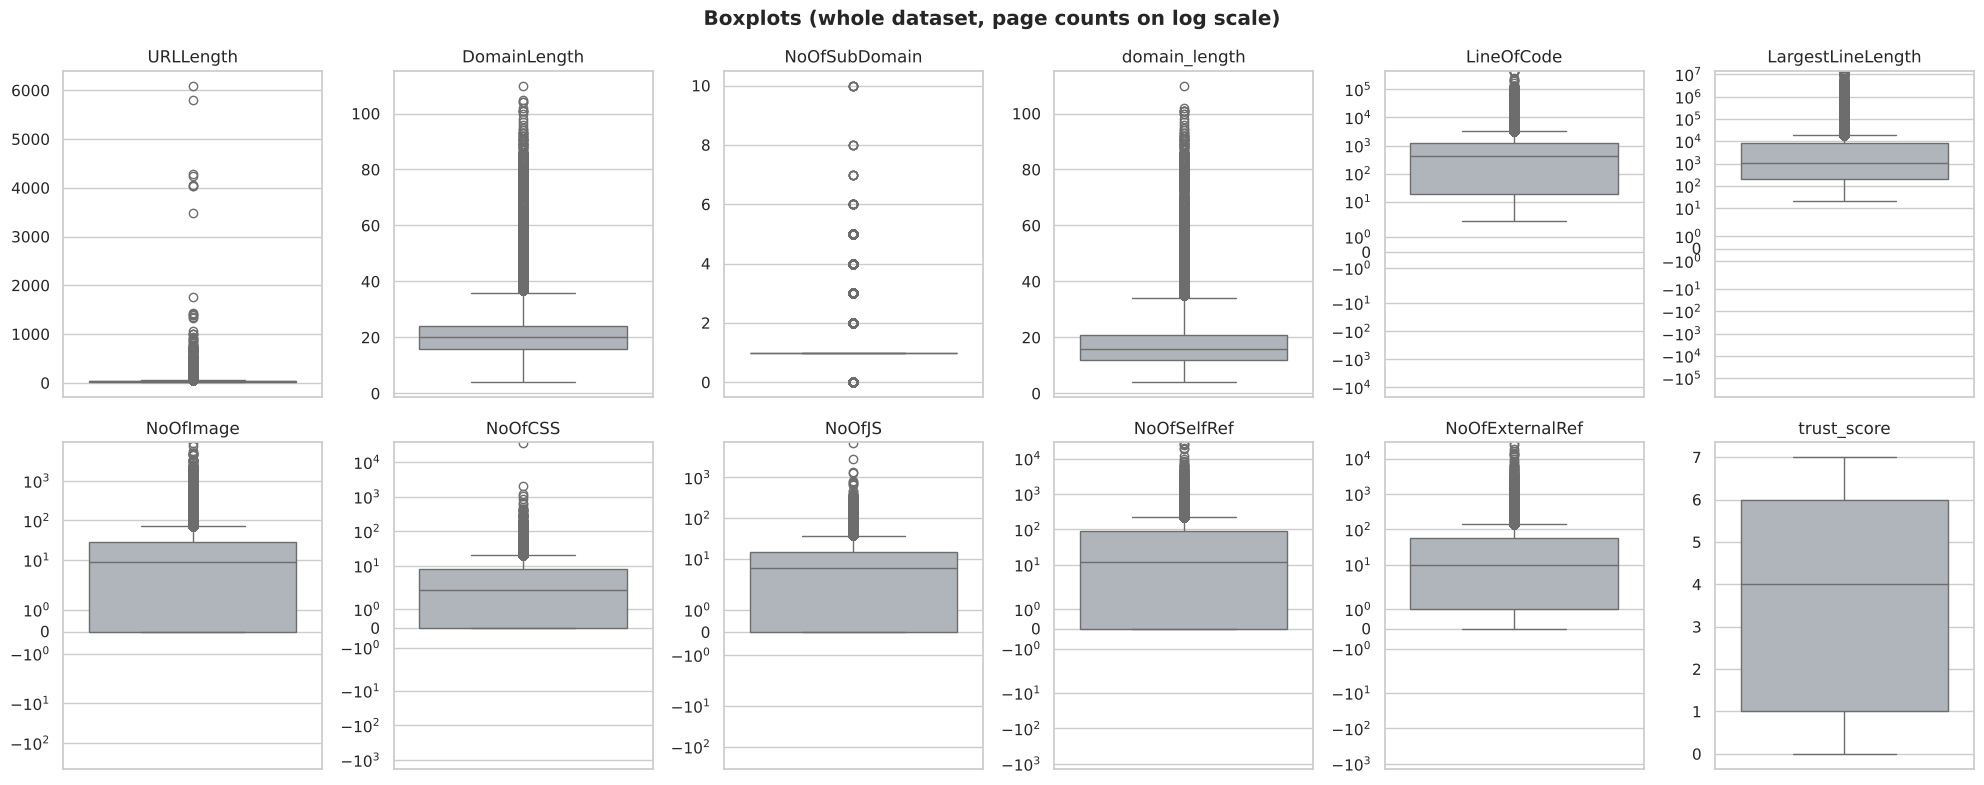

In [26]:
box_cols = ["URLLength", "DomainLength", "NoOfSubDomain", "domain_length", "LineOfCode", "LargestLineLength",
            "NoOfImage", "NoOfCSS", "NoOfJS", "NoOfSelfRef", "NoOfExternalRef", "trust_score"]
fig, axes = plt.subplots(2, 6, figsize=(20, 8))
for ax, c in zip(axes.flat, box_cols):
    sns.boxplot(y=clean[c], ax=ax, color="#adb5bd")
    ax.set_title(c); ax.set_ylabel("")
    if c in page_counts:
        ax.set_yscale("symlog")
plt.suptitle("Boxplots (whole dataset, page counts on log scale)", fontweight="bold")
save("box_univariate")

## 6. EDA – bivariate & multivariate analysis

### 6.1 Numeric features by class

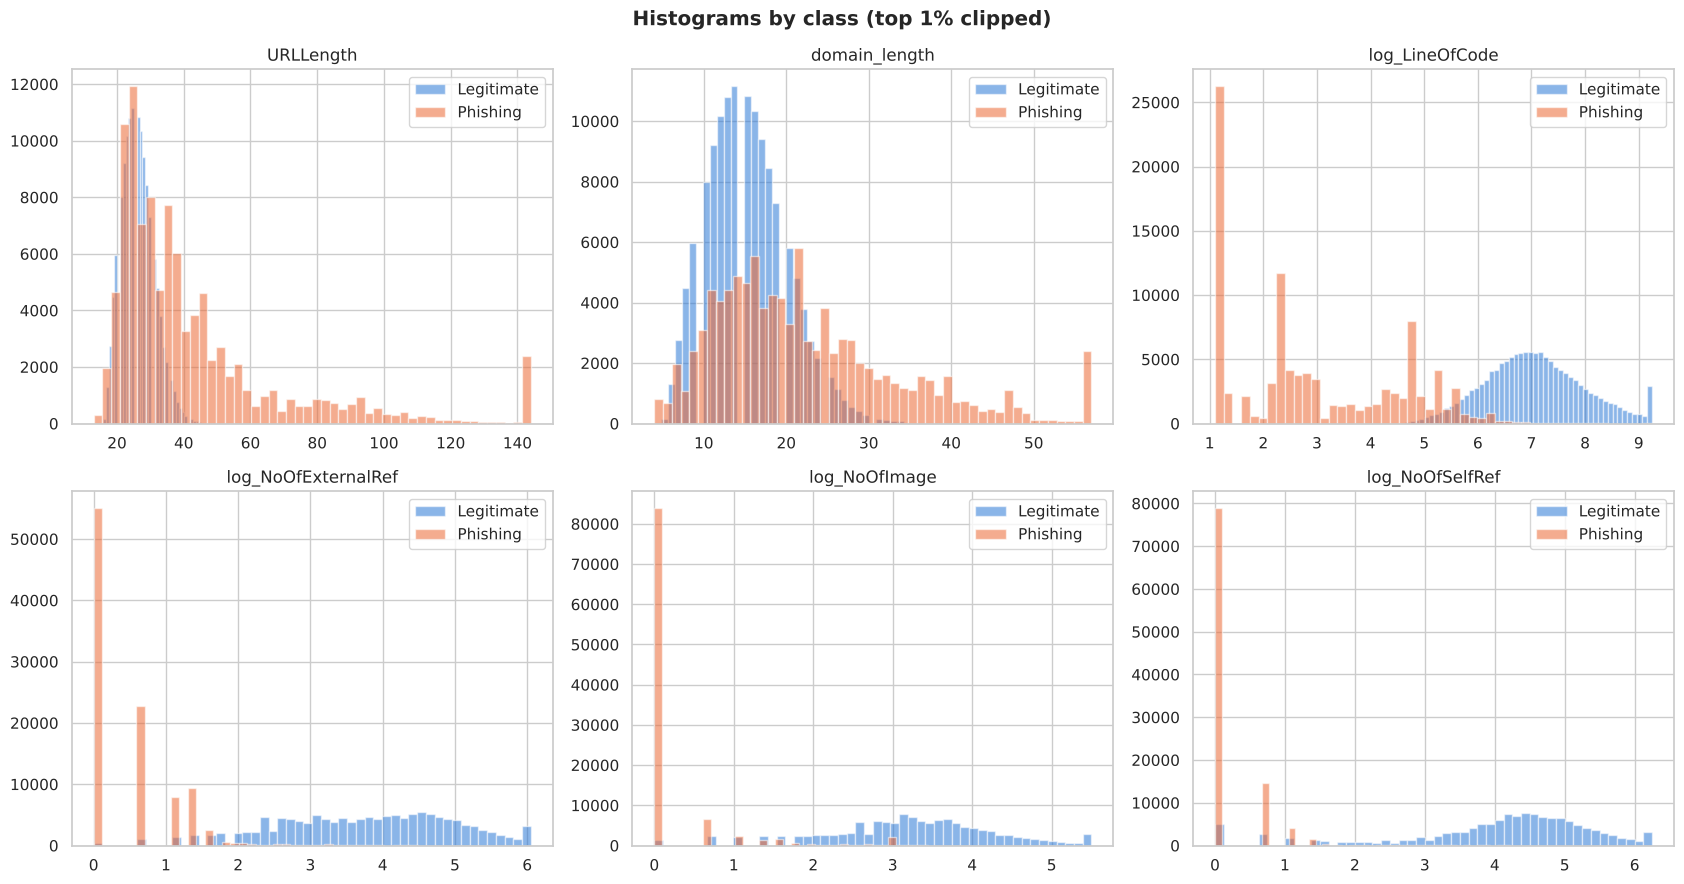

In [27]:
plot_df = clean.assign(**{f"log_{c}": np.log1p(clean[c]) for c in page_counts})
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, c in zip(axes.flat, ["URLLength", "domain_length", "log_LineOfCode", "log_NoOfExternalRef",
                             "log_NoOfImage", "log_NoOfSelfRef"]):
    data = plot_df[c].clip(upper=plot_df[c].quantile(0.99))
    for lab in ORDER:
        ax.hist(data[plot_df["label_name"] == lab], bins=50, alpha=0.55, color=PAL[lab], label=lab)
    ax.set_title(c); ax.legend()
plt.suptitle("Histograms by class (top 1% clipped)", fontweight="bold")
save("hist_by_class")

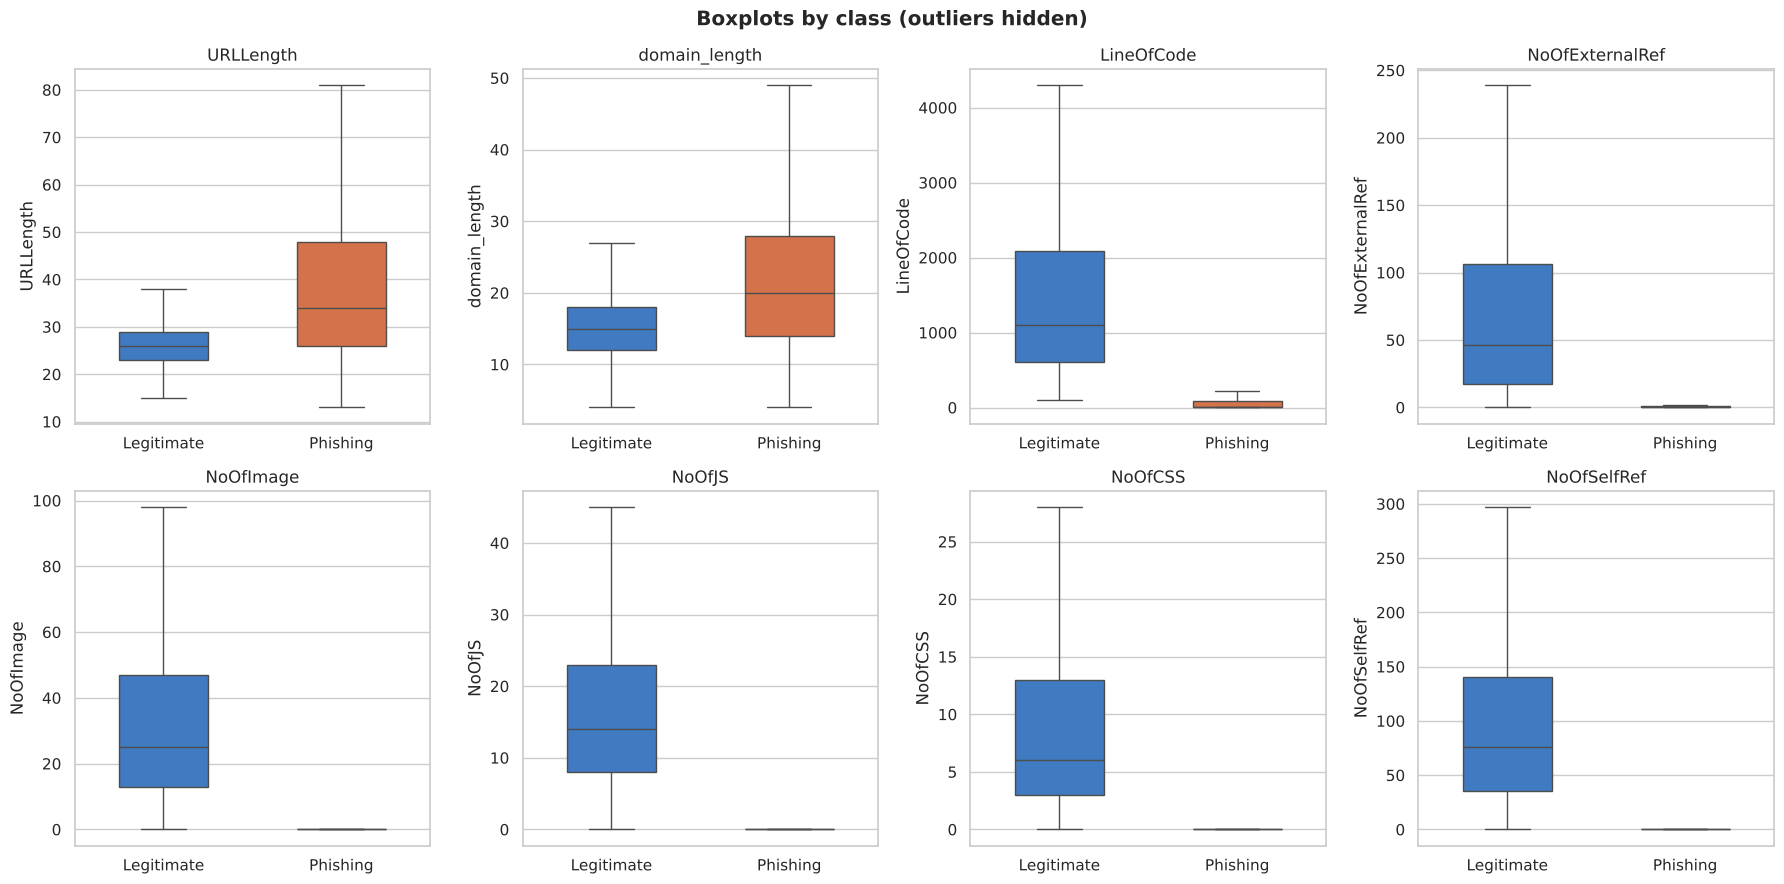

In [28]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, c in zip(axes.flat, ["URLLength", "domain_length", "LineOfCode", "NoOfExternalRef",
                             "NoOfImage", "NoOfJS", "NoOfCSS", "NoOfSelfRef"]):
    sns.boxplot(data=clean, x="label_name", y=c, order=ORDER, palette=PAL, ax=ax, showfliers=False, width=0.5)
    ax.set_title(c); ax.set_xlabel("")
plt.suptitle("Boxplots by class (outliers hidden)", fontweight="bold")
save("box_by_class")

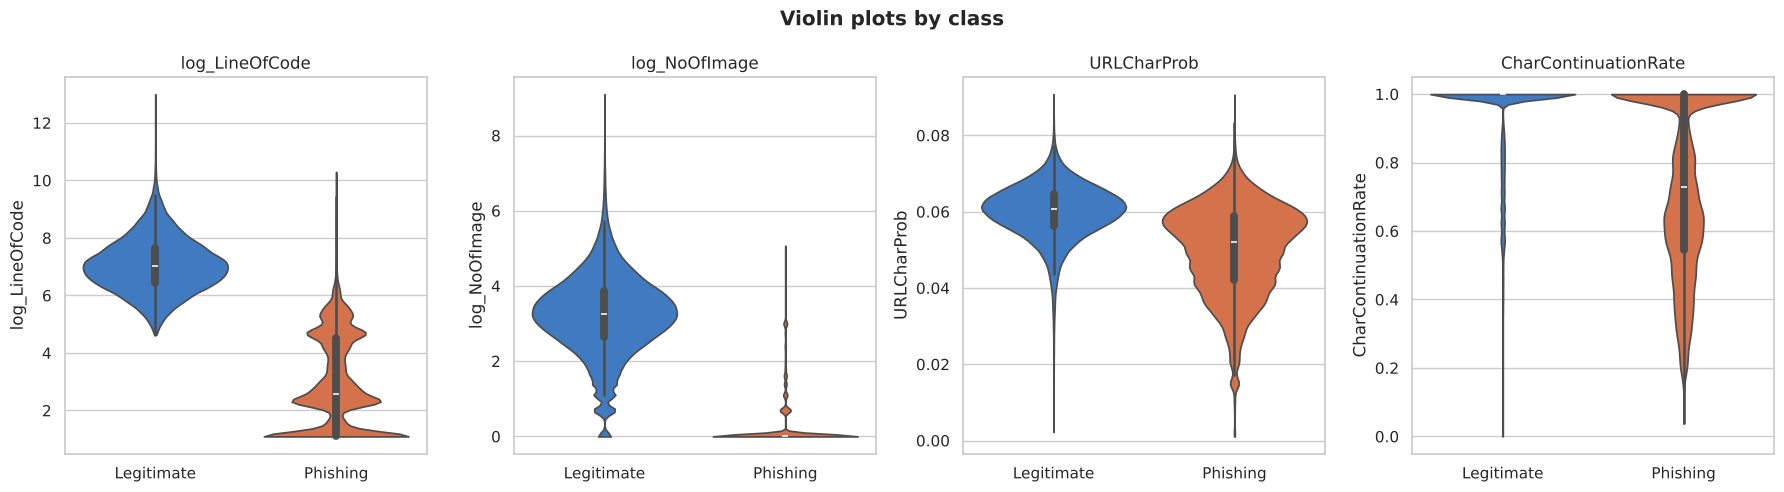

In [29]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, c in zip(axes, ["log_LineOfCode", "log_NoOfImage", "URLCharProb", "CharContinuationRate"]):
    sns.violinplot(data=plot_df, x="label_name", y=c, order=ORDER, palette=PAL, ax=ax, cut=0)
    ax.set_title(c); ax.set_xlabel("")
plt.suptitle("Violin plots by class", fontweight="bold")
save("violin_by_class")

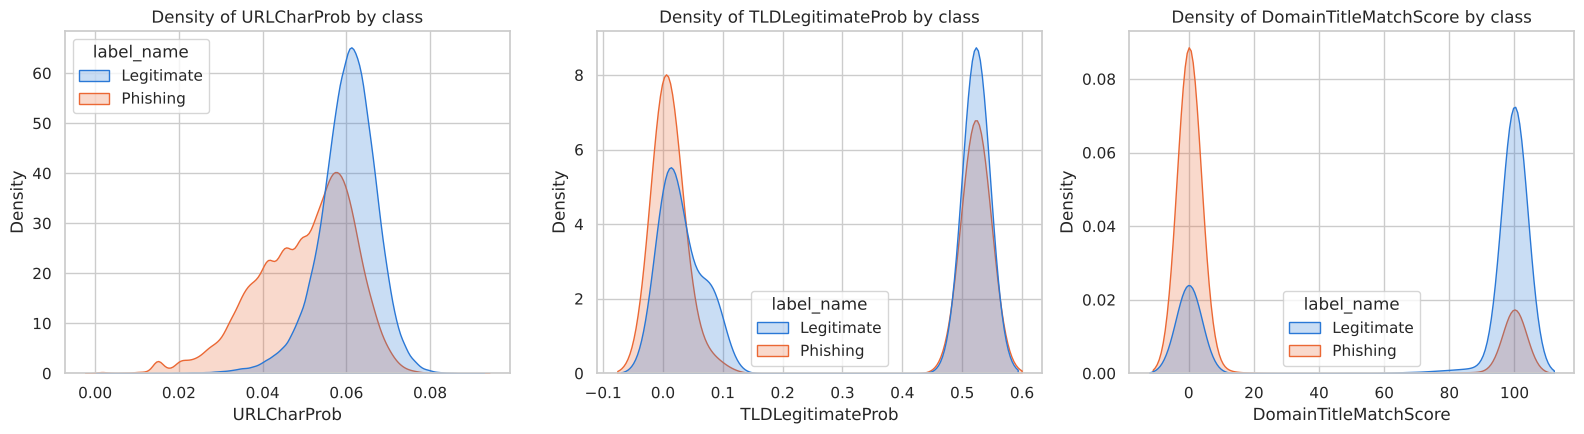

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, c in zip(axes, ["URLCharProb", "TLDLegitimateProb", "DomainTitleMatchScore"]):
    sns.kdeplot(data=clean, x=c, hue="label_name", hue_order=ORDER, palette=PAL, fill=True,
                common_norm=False, ax=ax)
    ax.set_title(f"Density of {c} by class")
save("kde_by_class")

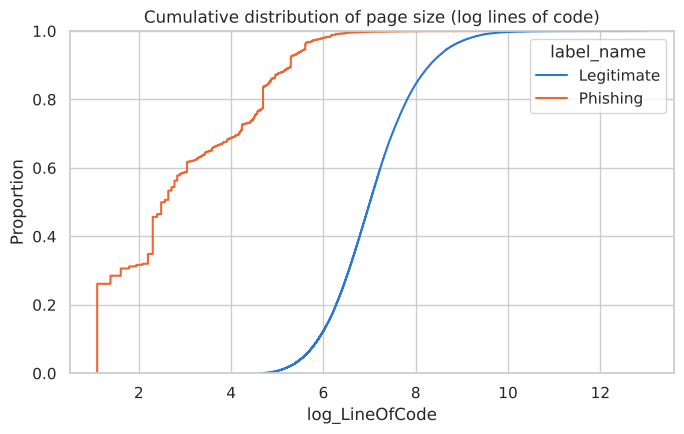

In [31]:
plt.figure(figsize=(7, 4.5))
sns.ecdfplot(data=plot_df, x="log_LineOfCode", hue="label_name", hue_order=ORDER, palette=PAL)
plt.title("Cumulative distribution of page size (log lines of code)")
save("ecdf_page_size")

In [32]:
# median of each feature per class
compare_cols = ["URLLength", "domain_length", "domain_digits", "domain_hyphens", "LineOfCode", "NoOfImage",
                "NoOfCSS", "NoOfJS", "NoOfSelfRef", "NoOfExternalRef", "trust_score"]
clean.groupby("label_name")[compare_cols].median().T

label_name,Legitimate,Phishing
URLLength,26.0,34.0
domain_length,15.0,20.0
domain_digits,0.0,0.0
domain_hyphens,0.0,0.0
LineOfCode,1105.0,12.0
NoOfImage,25.0,0.0
NoOfCSS,6.0,0.0
NoOfJS,14.0,0.0
NoOfSelfRef,76.0,0.0
NoOfExternalRef,46.0,0.0


### 6.2 Binary features by class

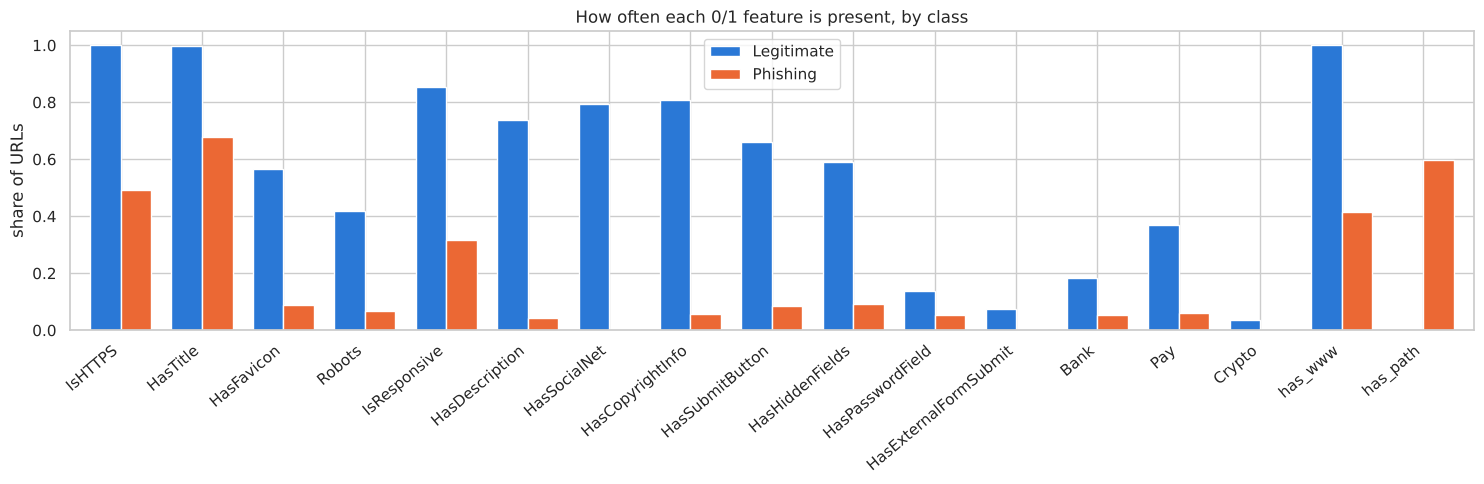

In [33]:
flags = ["IsHTTPS", "HasTitle", "HasFavicon", "Robots", "IsResponsive", "HasDescription", "HasSocialNet",
         "HasCopyrightInfo", "HasSubmitButton", "HasHiddenFields", "HasPasswordField", "HasExternalFormSubmit",
         "Bank", "Pay", "Crypto", "has_www", "has_path"]
share = clean.groupby("label_name")[flags].mean().T
share.plot.bar(figsize=(15, 5), color=[PAL[k] for k in ORDER], width=0.75)
plt.title("How often each 0/1 feature is present, by class"); plt.ylabel("share of URLs")
plt.xticks(rotation=40, ha="right"); plt.legend(title="")
save("bar_binary_by_class")

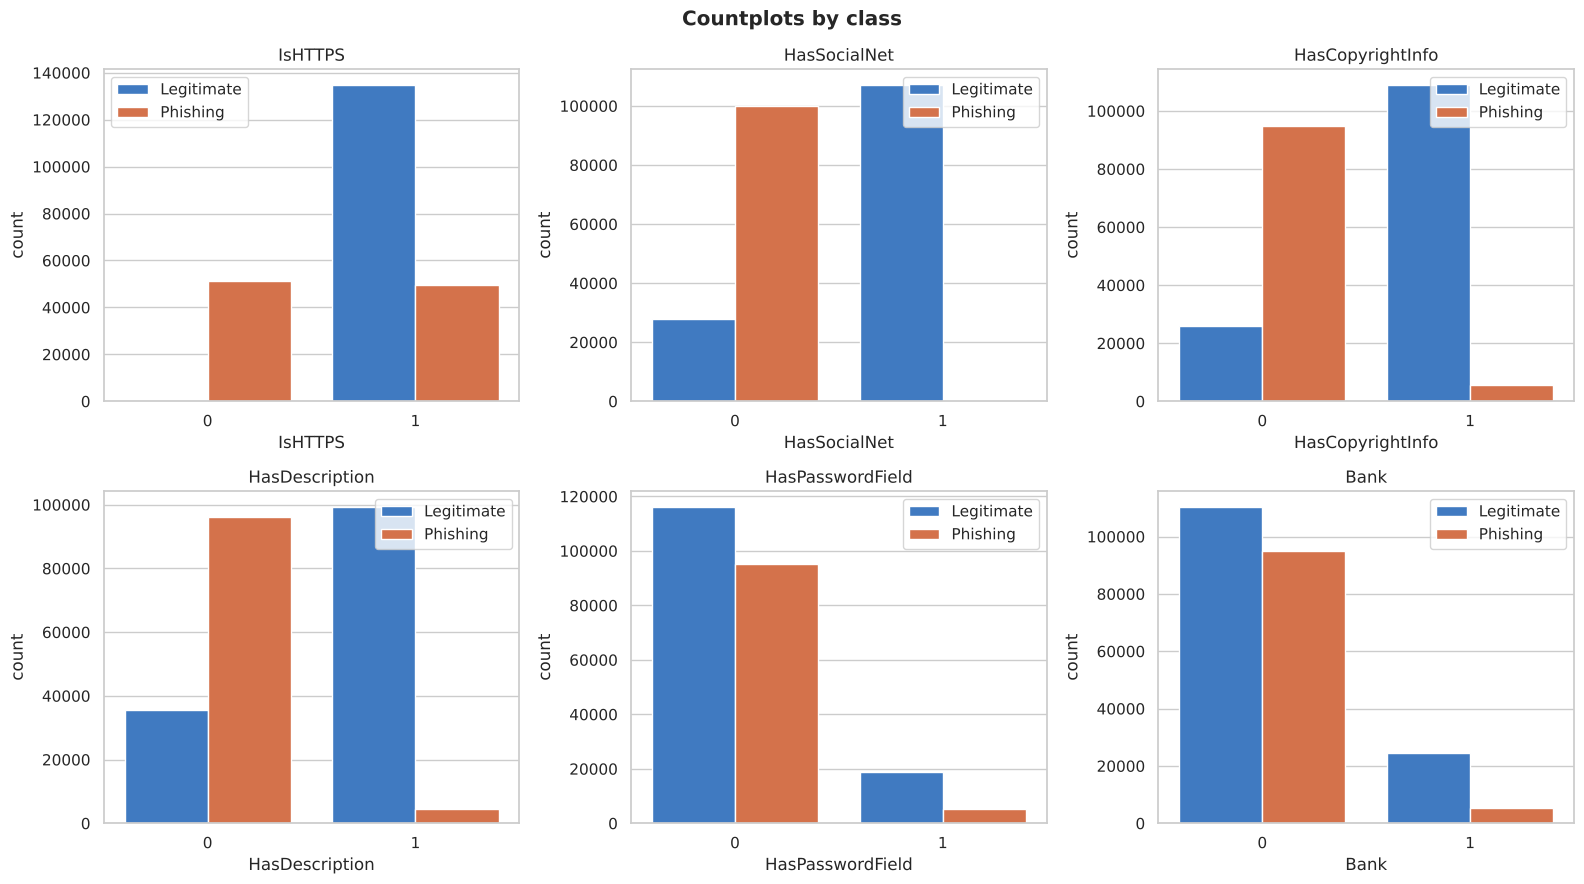

In [34]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, c in zip(axes.flat, ["IsHTTPS", "HasSocialNet", "HasCopyrightInfo", "HasDescription",
                             "HasPasswordField", "Bank"]):
    sns.countplot(data=clean, x=c, hue="label_name", hue_order=ORDER, palette=PAL, ax=ax)
    ax.set_title(c); ax.legend(title="")
plt.suptitle("Countplots by class", fontweight="bold")
save("count_binary_by_class")

### 6.3 Phishing rate by category

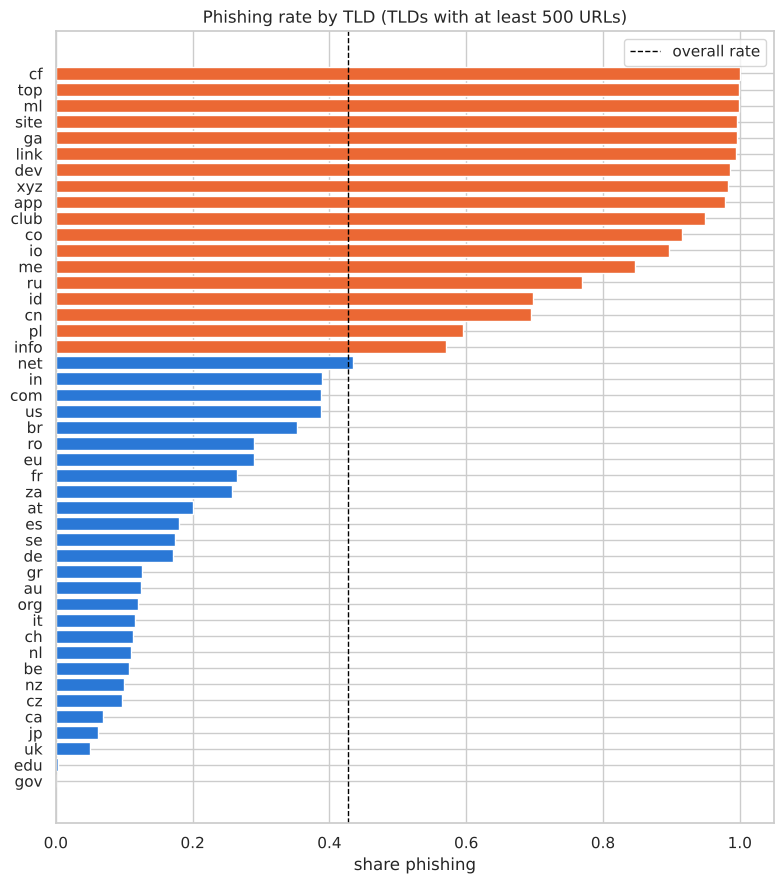

,rate,n
TLD,,
cf,1.000000,1203
top,0.999141,2327
ml,0.998994,994
site,0.996599,1470
ga,0.996400,1111
link,0.994417,1433
dev,0.985788,2322
xyz,0.982982,1469
app,0.978352,6467


In [35]:
tld_rate = (clean.groupby("TLD")["is_phishing"].agg(rate="mean", n="size")
            .query("n >= 500").sort_values("rate"))
plt.figure(figsize=(8, 9))
plt.barh(tld_rate.index, tld_rate["rate"],
         color=[PAL["Phishing"] if r > 0.5 else PAL["Legitimate"] for r in tld_rate["rate"]])
plt.axvline(clean["is_phishing"].mean(), color="black", ls="--", lw=1, label="overall rate")
plt.title("Phishing rate by TLD (TLDs with at least 500 URLs)"); plt.xlabel("share phishing"); plt.legend()
save("rate_by_tld")
tld_rate.sort_values("rate", ascending=False).head(10)

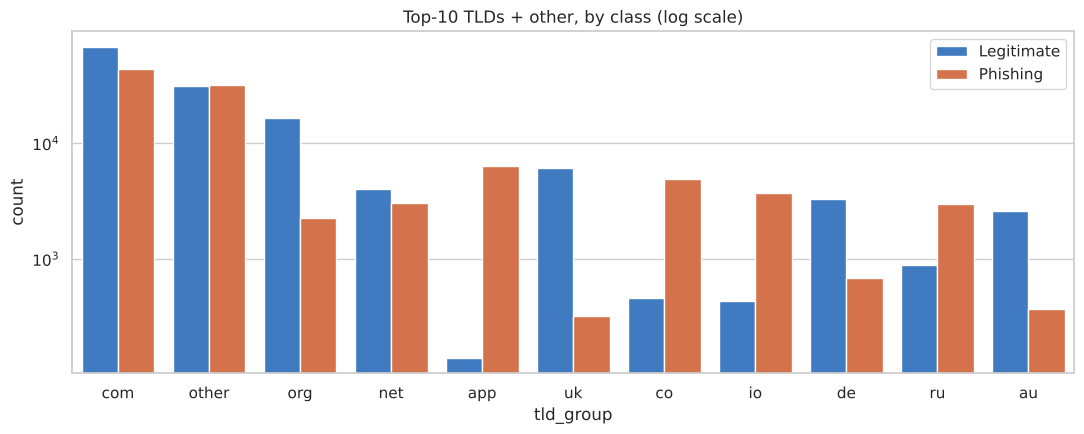

In [36]:
plt.figure(figsize=(11, 4.5))
sns.countplot(data=clean, x="tld_group", hue="label_name", hue_order=ORDER, palette=PAL,
              order=clean["tld_group"].value_counts().index)
plt.yscale("log"); plt.title("Top-10 TLDs + other, by class (log scale)"); plt.legend(title="")
save("count_tld_group_by_class")

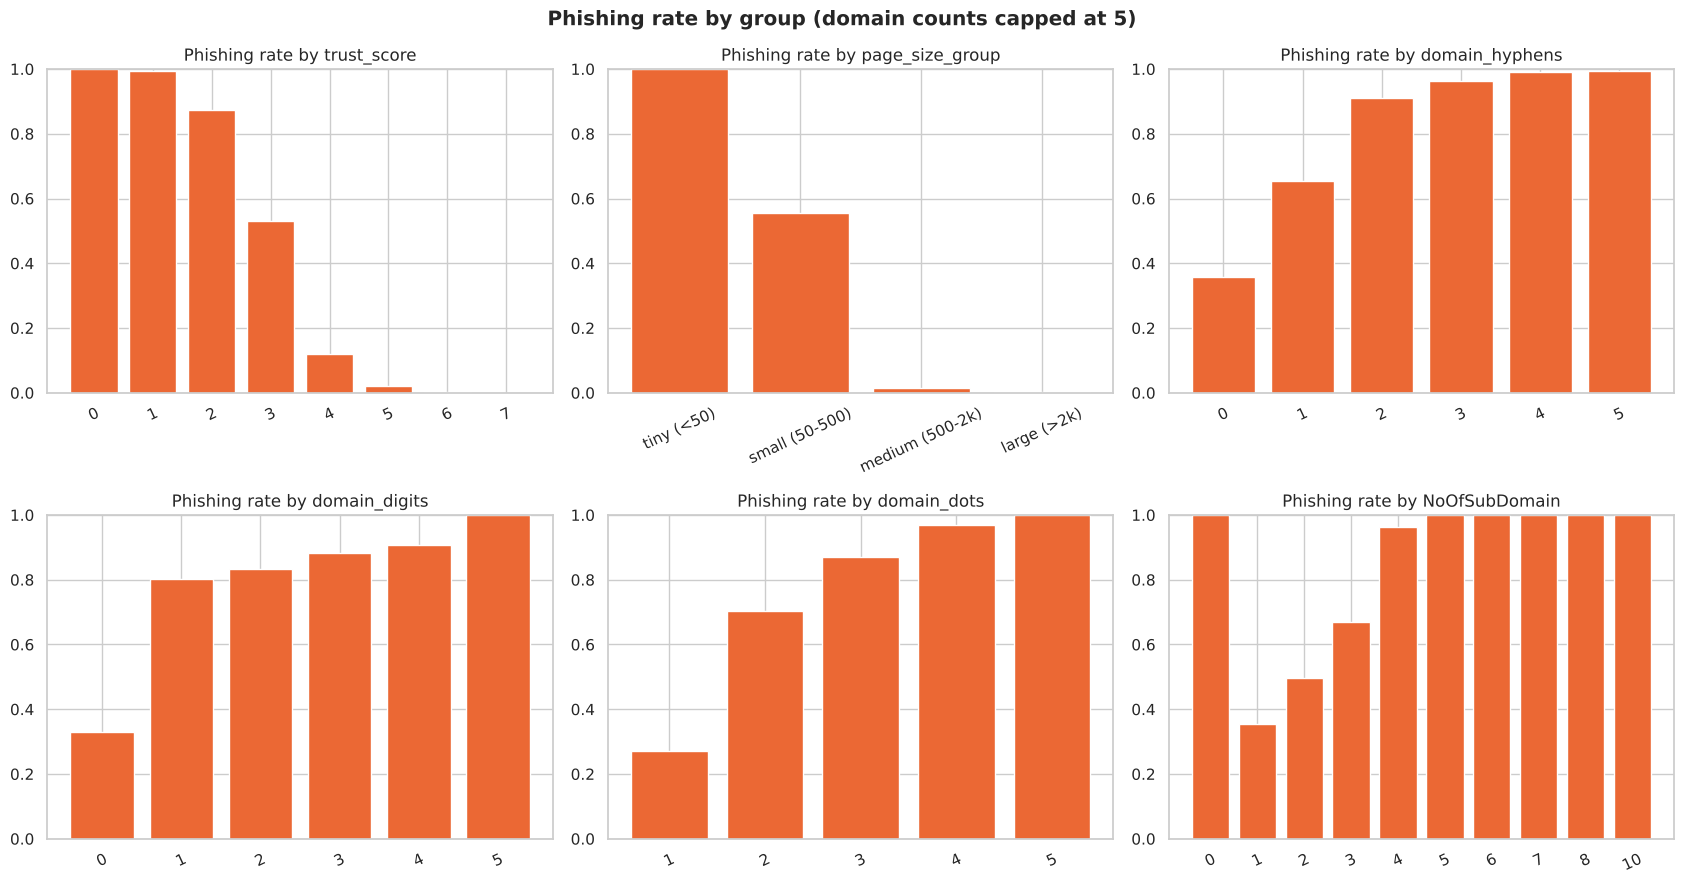

In [37]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, c in zip(axes.flat, ["trust_score", "page_size_group", "domain_hyphens", "domain_digits",
                             "domain_dots", "NoOfSubDomain"]):
    data = clean[c].clip(upper=5) if c in ("domain_hyphens", "domain_digits", "domain_dots") else clean[c]
    rate = clean.groupby(data, observed=True)["is_phishing"].mean()
    ax.bar(rate.index.astype(str), rate.values, color=PAL["Phishing"])
    ax.set_ylim(0, 1); ax.set_title(f"Phishing rate by {c}"); ax.tick_params(axis="x", rotation=25)
plt.suptitle("Phishing rate by group (domain counts capped at 5)", fontweight="bold")
save("rate_by_group")

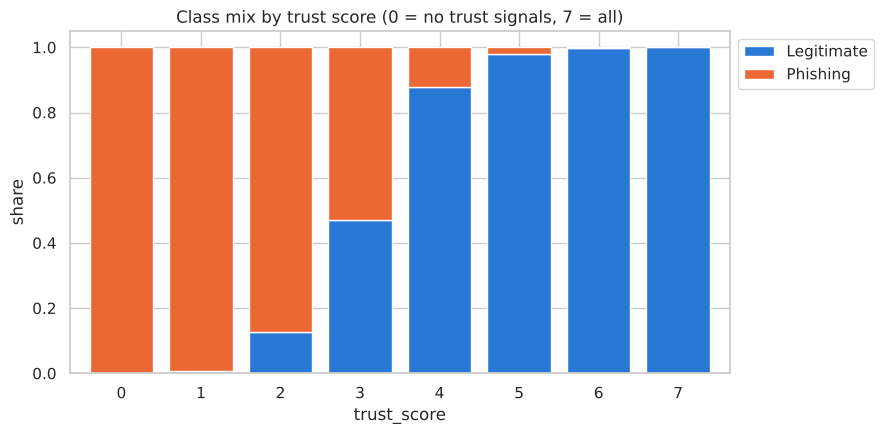

In [38]:
# 100% stacked bars: class mix inside each trust score
mix = pd.crosstab(clean["trust_score"], clean["label_name"], normalize="index")[ORDER]
mix.plot.bar(stacked=True, figsize=(9, 4.5), color=[PAL[k] for k in ORDER], width=0.8)
plt.title("Class mix by trust score (0 = no trust signals, 7 = all)"); plt.ylabel("share"); plt.xticks(rotation=0)
plt.legend(title="", bbox_to_anchor=(1, 1))
save("stacked_trust_score")

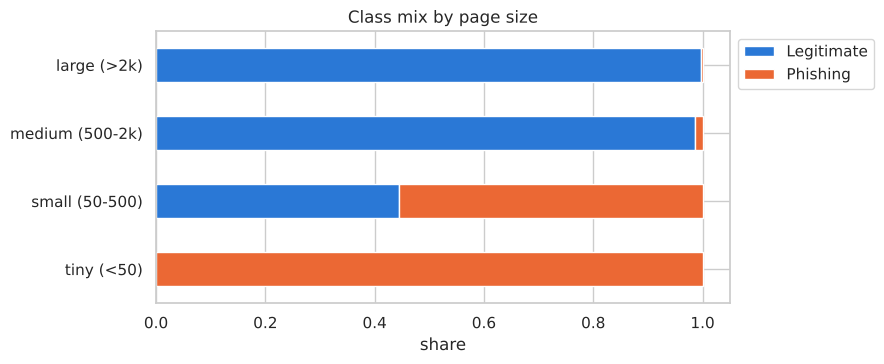

In [39]:
mix = pd.crosstab(clean["page_size_group"], clean["label_name"], normalize="index")[ORDER]
mix.plot.barh(stacked=True, figsize=(9, 3.8), color=[PAL[k] for k in ORDER])
plt.title("Class mix by page size"); plt.xlabel("share"); plt.ylabel("")
plt.legend(title="", bbox_to_anchor=(1, 1))
save("stacked_page_size")

### 6.4 Scatter plots

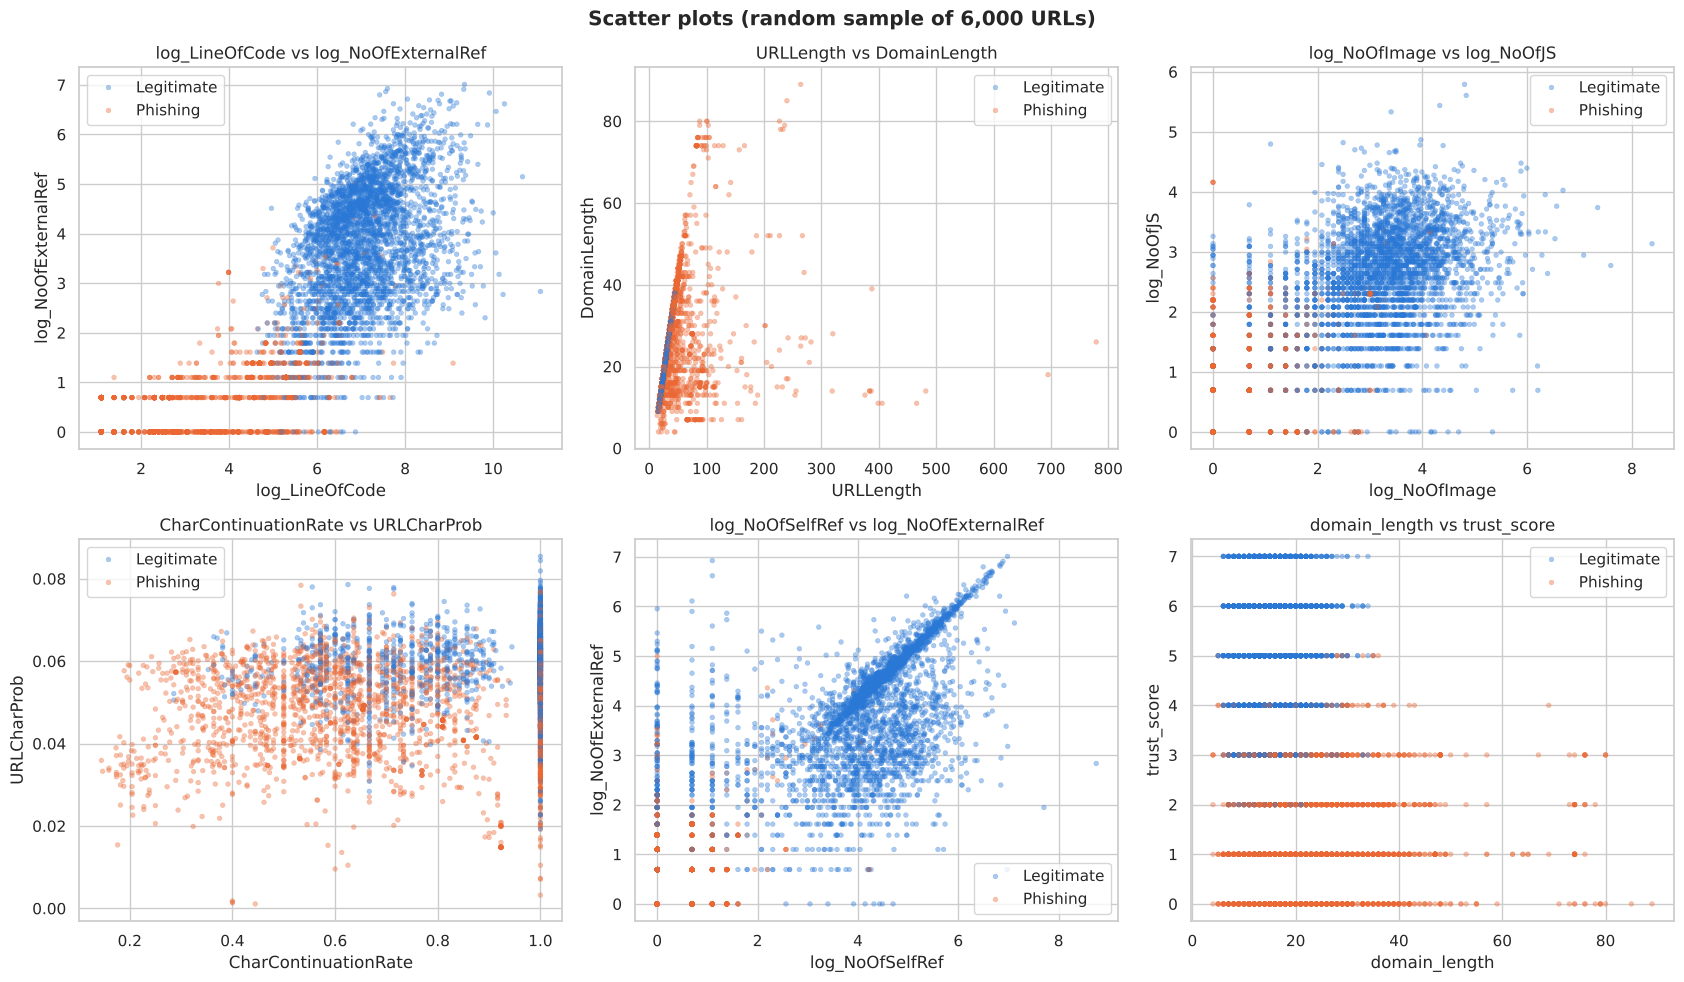

In [40]:
sample = plot_df.sample(6000, random_state=SEED)
pairs = [("log_LineOfCode", "log_NoOfExternalRef"), ("URLLength", "DomainLength"),
         ("log_NoOfImage", "log_NoOfJS"), ("CharContinuationRate", "URLCharProb"),
         ("log_NoOfSelfRef", "log_NoOfExternalRef"), ("domain_length", "trust_score")]
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for ax, (x, y) in zip(axes.flat, pairs):
    sns.scatterplot(data=sample, x=x, y=y, hue="label_name", hue_order=ORDER, palette=PAL,
                    s=12, alpha=0.4, edgecolor=None, ax=ax)
    ax.set_title(f"{x} vs {y}"); ax.legend(title="")
plt.suptitle("Scatter plots (random sample of 6,000 URLs)", fontweight="bold")
save("scatter_grid")

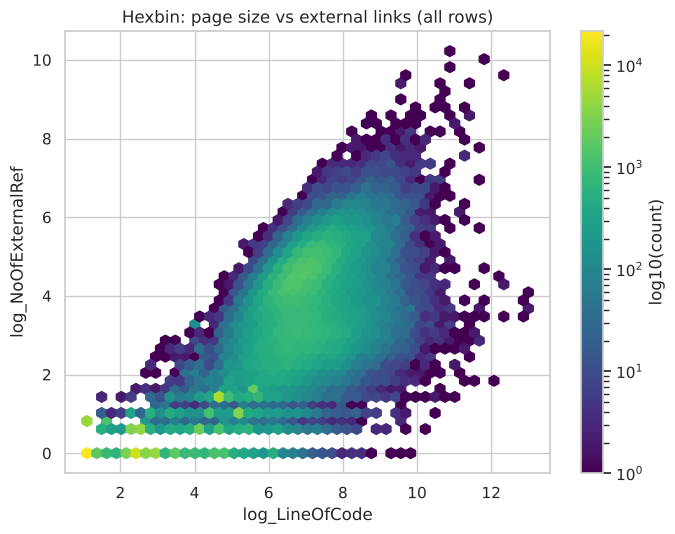

In [41]:
plt.figure(figsize=(7, 5.5))
plt.hexbin(plot_df["log_LineOfCode"], plot_df["log_NoOfExternalRef"], gridsize=45, cmap="viridis", bins="log")
plt.colorbar(label="log10(count)")
plt.xlabel("log_LineOfCode"); plt.ylabel("log_NoOfExternalRef")
plt.title("Hexbin: page size vs external links (all rows)")
save("hexbin_page_links")

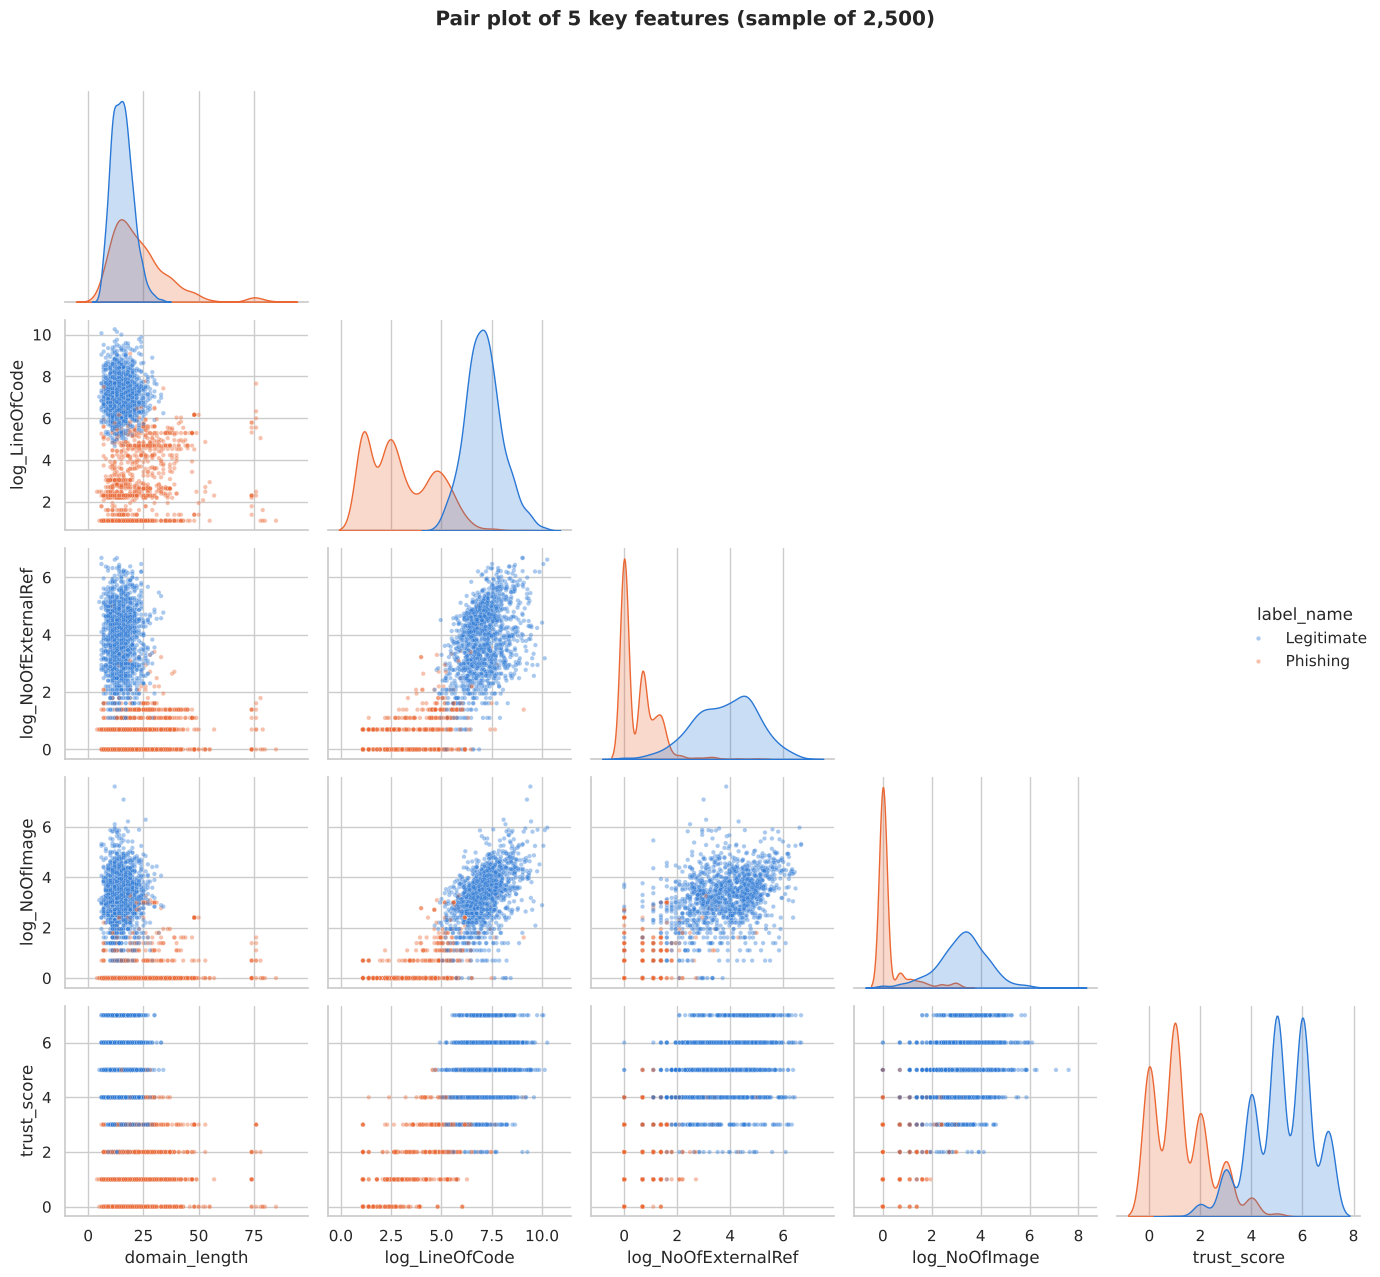

In [42]:
g = sns.pairplot(plot_df.sample(2500, random_state=SEED),
                 vars=["domain_length", "log_LineOfCode", "log_NoOfExternalRef", "log_NoOfImage", "trust_score"],
                 hue="label_name", hue_order=ORDER, palette=PAL, plot_kws={"s": 10, "alpha": 0.4},
                 corner=True)
g.figure.suptitle("Pair plot of 5 key features (sample of 2,500)", y=1.02, fontweight="bold")
save("pairplot")

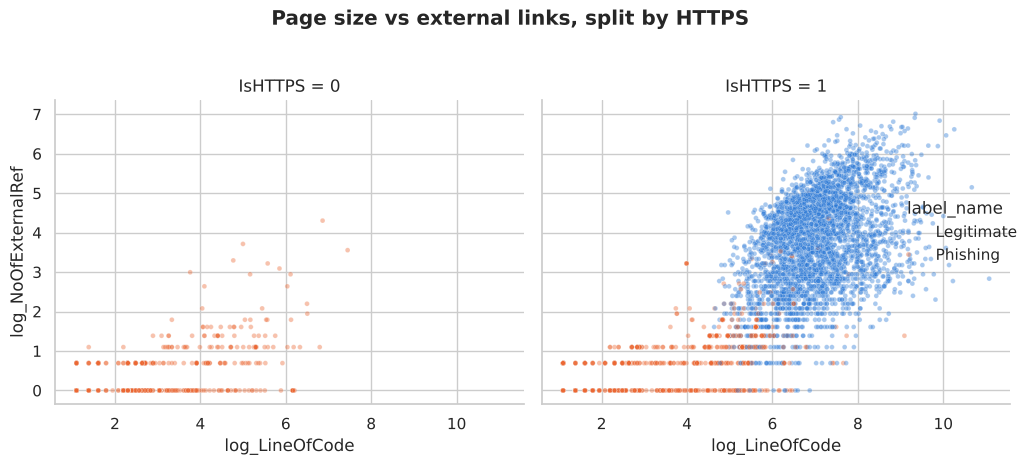

In [43]:
g = sns.relplot(data=sample, x="log_LineOfCode", y="log_NoOfExternalRef", hue="label_name", hue_order=ORDER,
                palette=PAL, col="IsHTTPS", s=12, alpha=0.4, height=4.5)
g.figure.suptitle("Page size vs external links, split by HTTPS", y=1.03, fontweight="bold")
save("scatter_by_https")

### 6.5 Correlation

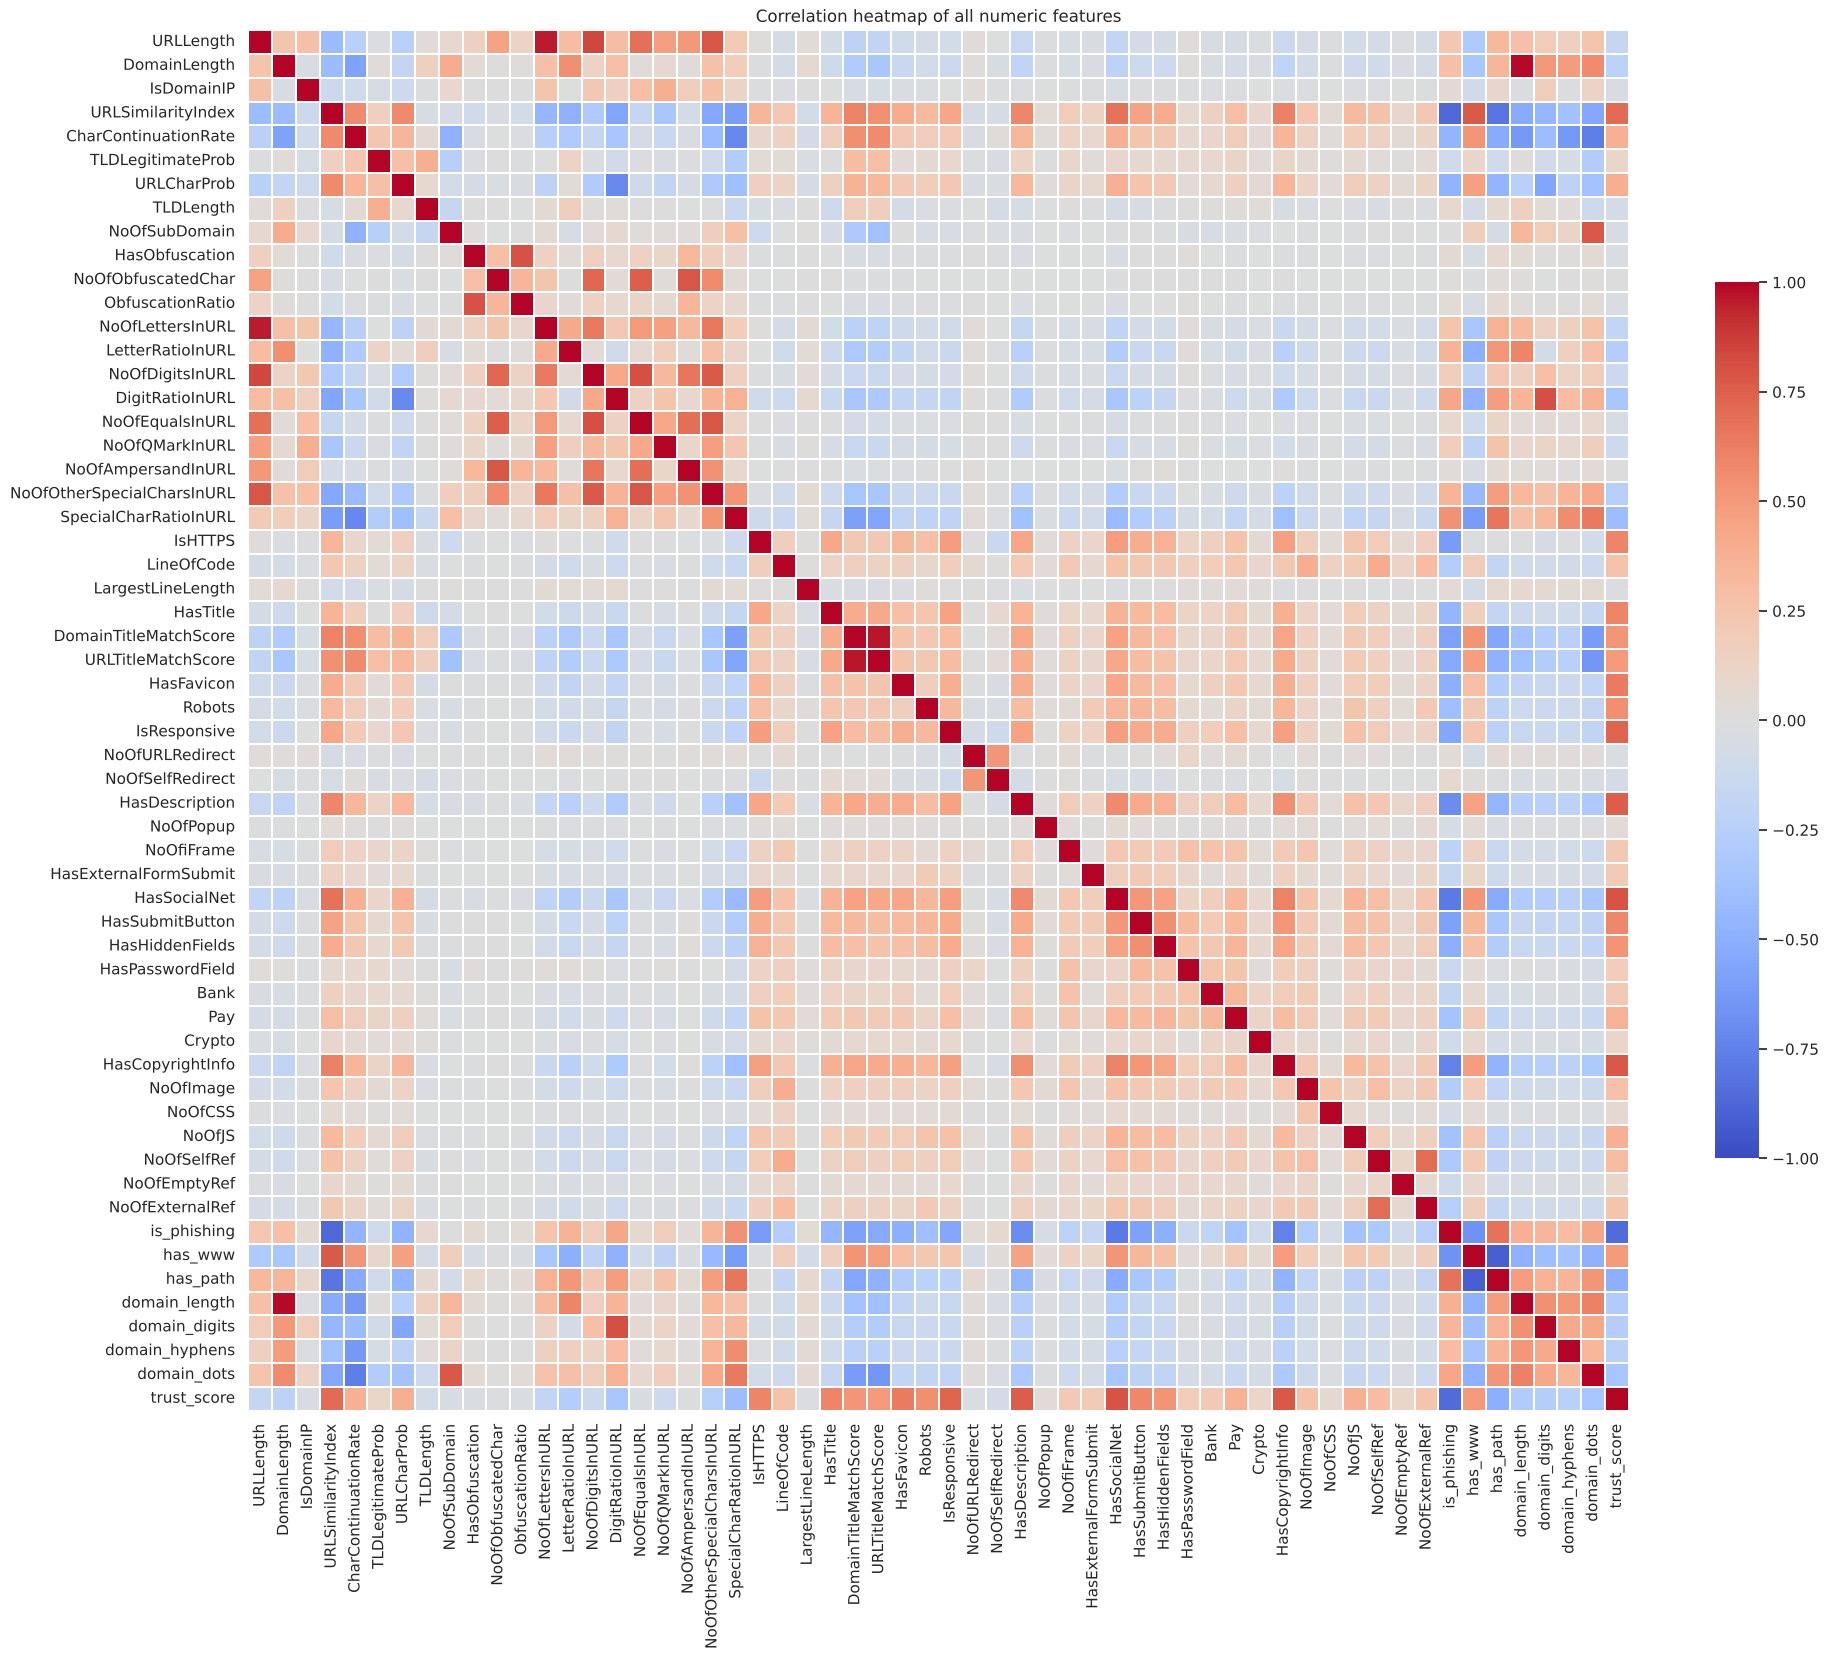

In [44]:
num = clean.select_dtypes("number")
corr = num.corr()
plt.figure(figsize=(20, 17))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, linewidths=0.2,
            cbar_kws={"shrink": 0.6})
plt.title("Correlation heatmap of all numeric features")
save("corr_all")

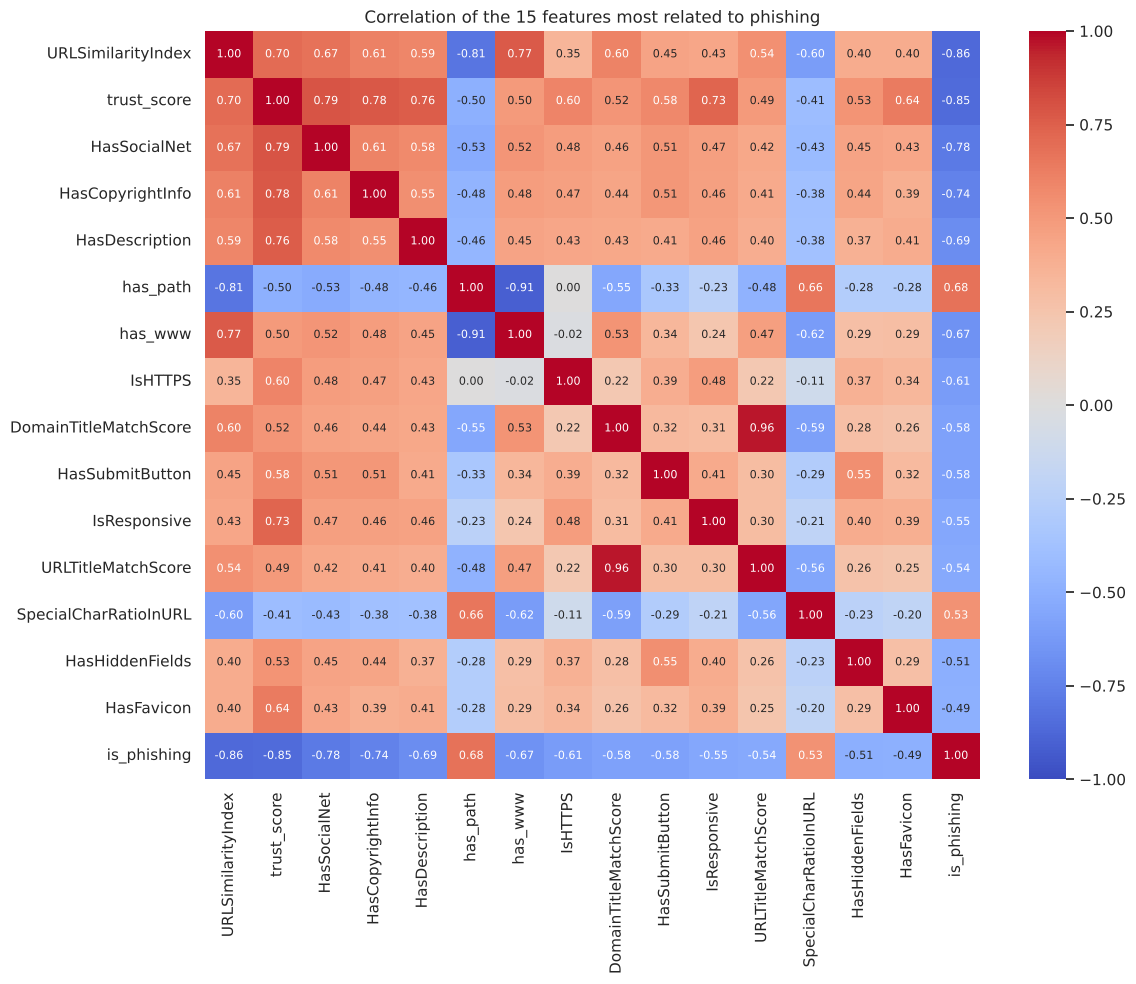

In [45]:
target_corr = corr["is_phishing"].drop("is_phishing").dropna()
top15 = target_corr.abs().sort_values(ascending=False).head(15).index
plt.figure(figsize=(12, 10))
sns.heatmap(num[list(top15) + ["is_phishing"]].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, annot_kws={"size": 8})
plt.title("Correlation of the 15 features most related to phishing")
save("corr_top15")

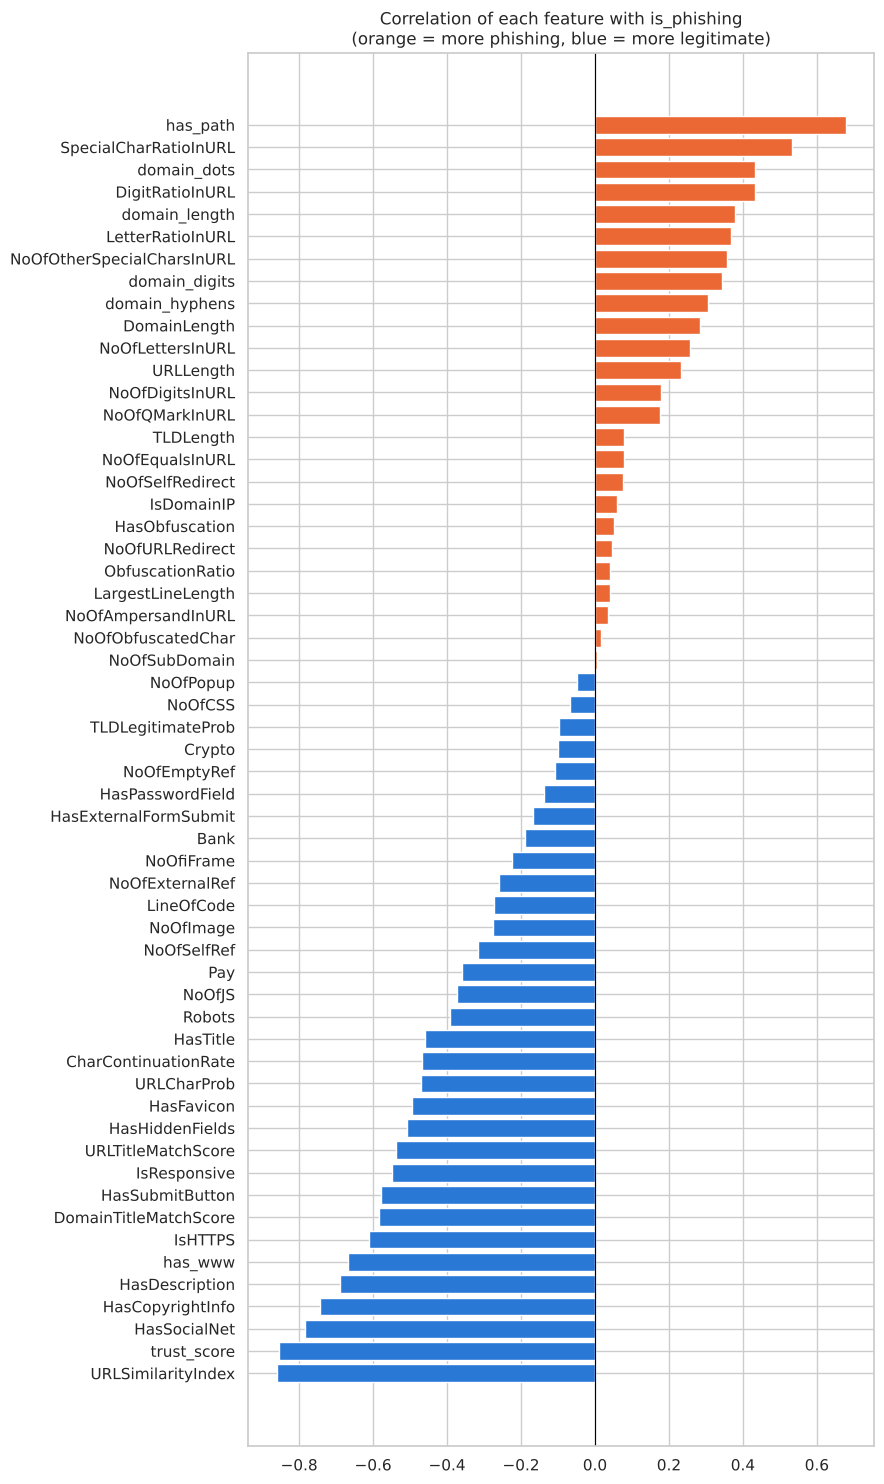

In [46]:
tc = target_corr.sort_values()
plt.figure(figsize=(9, 15))
plt.barh(tc.index, tc.values, color=[PAL["Phishing"] if v > 0 else PAL["Legitimate"] for v in tc.values])
plt.axvline(0, color="black", lw=0.8)
plt.title("Correlation of each feature with is_phishing\n(orange = more phishing, blue = more legitimate)")
save("corr_with_target")

In [47]:
# pairs of columns that are almost copies of each other (|r| > 0.9)
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
high = upper.stack().loc[lambda s: s.abs() > 0.9].sort_values(key=abs, ascending=False)
high.round(3).to_frame("correlation")

,,correlation
DomainLength,domain_length,0.986
DomainTitleMatchScore,URLTitleMatchScore,0.961
URLLength,NoOfLettersInURL,0.956
has_www,has_path,-0.908


### 6.6 Multivariate: two features together

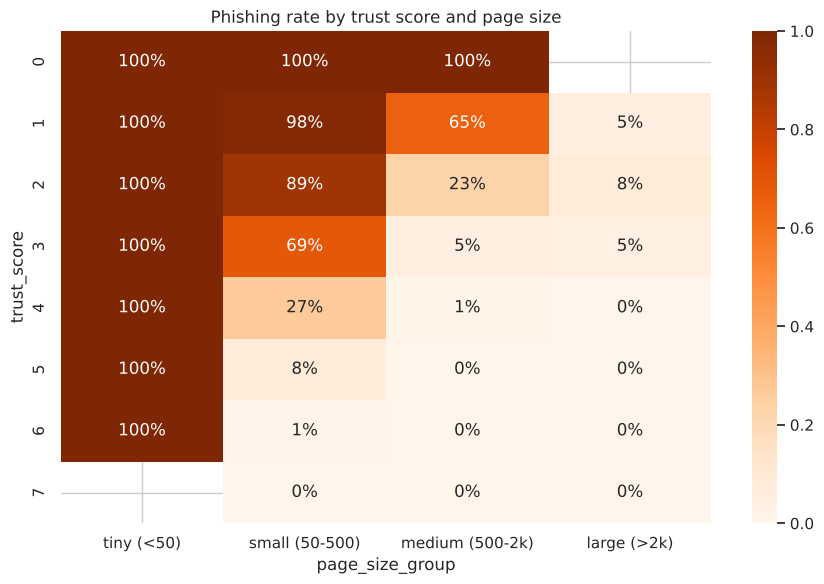

In [48]:
pivot = clean.pivot_table(index="trust_score", columns="page_size_group", values="is_phishing",
                          aggfunc="mean", observed=True)
plt.figure(figsize=(9, 6))
sns.heatmap(pivot, annot=True, fmt=".0%", cmap="Oranges", vmin=0, vmax=1)
plt.title("Phishing rate by trust score and page size")
save("heatmap_trust_page")

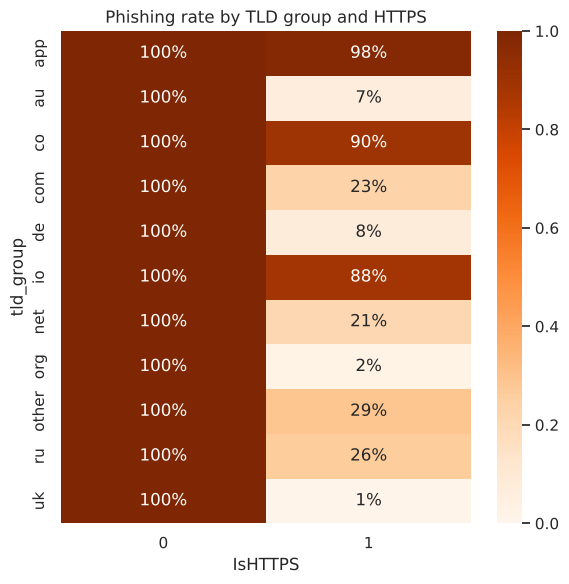

In [49]:
pivot = clean.pivot_table(index="tld_group", columns="IsHTTPS", values="is_phishing", aggfunc="mean")
plt.figure(figsize=(6, 6))
sns.heatmap(pivot, annot=True, fmt=".0%", cmap="Oranges", vmin=0, vmax=1)
plt.title("Phishing rate by TLD group and HTTPS")
save("heatmap_tld_https")

## 7. Leakage check

A column leaks the label when it gives away the answer because of how the
data was collected. A model trained on it but fail on real links. I used three simple checks.

### Check 1: is the column the same for every legitimate URL?

In [50]:
legit = clean[clean["is_phishing"] == 0]
phish = clean[clean["is_phishing"] == 1]
check1 = []
for c in num.columns.drop("is_phishing"):
    if legit[c].nunique() == 1:
        value = legit[c].iloc[0]
        check1.append({"column": c, "value for ALL legit URLs": value,
                       "phishing URLs with that value": (phish[c] == value).mean()})
check1 = pd.DataFrame(check1).sort_values("phishing URLs with that value")
check1

,column,value for ALL legit URLs,phishing URLs with that value
1,URLSimilarityIndex,100.0,0.007819
10,has_path,0.0,0.403034
9,has_www,1.0,0.415191
8,IsHTTPS,1.0,0.491226
6,NoOfQMarkInURL,0.0,0.939097
5,NoOfEqualsInURL,0.0,0.946329
7,NoOfAmpersandInURL,0.0,0.991216
0,IsDomainIP,0.0,0.993673
4,ObfuscationRatio,0.0,0.995195
3,NoOfObfuscatedChar,0.0,0.995195


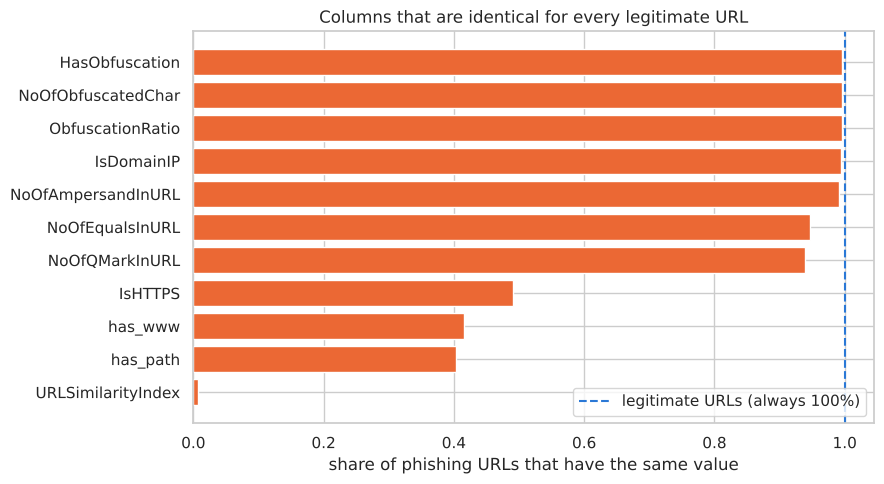

In [51]:
plt.figure(figsize=(9, 5))
plt.barh(check1["column"], check1["phishing URLs with that value"], color=PAL["Phishing"])
plt.axvline(1, color=PAL["Legitimate"], ls="--", label="legitimate URLs (always 100%)")
plt.xlabel("share of phishing URLs that have the same value")
plt.title("Columns that are identical for every legitimate URL"); plt.legend(loc="lower right")
save("leak_constant_columns")

### Check 2: how well does ONE column do on its own?
A tiny decision tree (depth 2) using a single column. Anything near 100% by itself is suspicious.

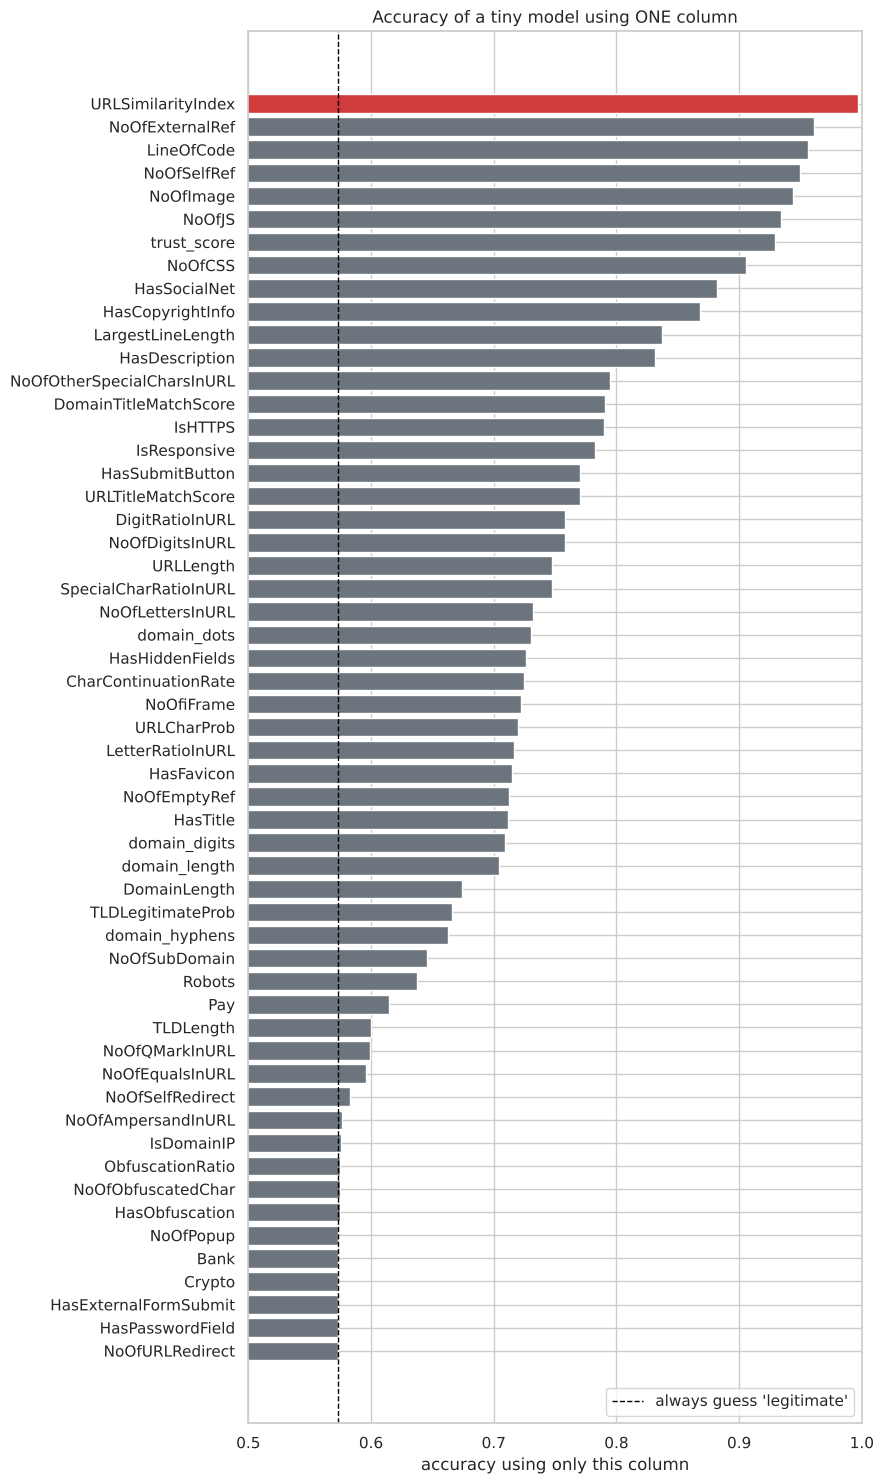

URLSimilarityIndex    99.67%
NoOfExternalRef       96.13%
LineOfCode            95.58%
NoOfSelfRef           94.93%
NoOfImage             94.38%
NoOfJS                93.41%
trust_score           92.89%
NoOfCSS               90.57%
dtype: str

In [52]:
features = [c for c in num.columns if c not in ("is_phishing", "has_www", "has_path")]
tr, te = train_test_split(clean.index, test_size=0.2, random_state=SEED, stratify=clean["is_phishing"])
single = {}
for c in features:
    tree = DecisionTreeClassifier(max_depth=2, random_state=SEED).fit(clean.loc[tr, [c]], clean.loc[tr, "is_phishing"])
    single[c] = (tree.predict(clean.loc[te, [c]]) == clean.loc[te, "is_phishing"]).mean()
single = pd.Series(single).sort_values()

plt.figure(figsize=(9, 15))
plt.barh(single.index, single.values, color=["#d03b3b" if v > 0.99 else "#6c757d" for v in single.values])
plt.axvline(clean["is_phishing"].value_counts(normalize=True).max(), color="black", ls="--", lw=1,
            label="always guess 'legitimate'")
plt.xlim(0.5, 1); plt.xlabel("accuracy using only this column"); plt.legend(loc="lower right")
plt.title("Accuracy of a tiny model using ONE column")
save("leak_single_feature_accuracy")
single.sort_values(ascending=False).head(8).map("{:.2%}".format)

### Check 3: how the legitimate links were written

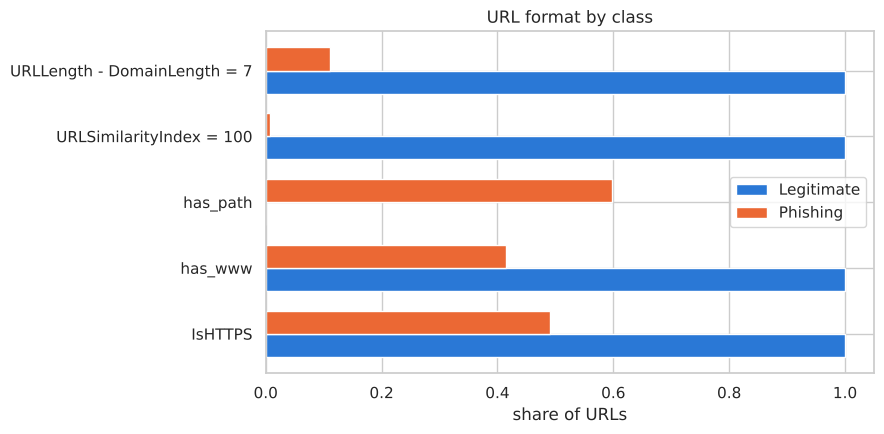

,IsHTTPS,has_www,has_path,URLSimilarityIndex = 100,URLLength - DomainLength = 7
label_name,,,,,
Legitimate,1.000,1.000,0.000,1.000,1.000
Phishing,0.491,0.415,0.597,0.008,0.111


In [53]:
fmt = clean.groupby("label_name")[["IsHTTPS", "has_www", "has_path"]].mean()
fmt["URLSimilarityIndex = 100"] = clean.groupby("label_name")["URLSimilarityIndex"].apply(lambda s: (s == 100).mean())
fmt["URLLength - DomainLength = 7"] = (clean["URLLength"] - clean["DomainLength"]).eq(7).groupby(clean["label_name"]).mean()
fmt.T.plot.barh(figsize=(9, 4.5), color=[PAL[k] for k in ORDER], width=0.7)
plt.title("URL format by class"); plt.xlabel("share of URLs"); plt.legend(title="")
save("leak_url_format")
fmt.round(3)

In [54]:
rule = ((clean["has_www"] == 1) & (clean["has_path"] == 0) & (clean["IsHTTPS"] == 1)).astype(int)
acc = ((1 - rule) == clean["is_phishing"]).mean()
print(f"Simple rule 'https://www. and no path => legitimate' is right for {acc:.1%} of URLs")

Simple rule 'https://www. and no path => legitimate' is right for 99.7% of URLs


**What this shows**
- Every legitimate link has https://www.something.com in it. So URLLength − DomainLength
  is always exactly 7 for real sites (the https:// part). 
- URLSimilarityIndex is 100 for every legitimate URL and gets 99.7% alone. This is the biggest leak. According to
  the dataset paper it measures how similar a URL is to known legitimate URLs, and the legitimate URLs were taken
  from that kind of list. The column has to be dropped.
- IsHTTPS is 1 for every legitimate URL but only for about half of the phishing ones. In real life most phishing
  sites use HTTPS too (certificates are free), so this is about how the data was collected (this is based on this dataset only).
- That means every column counted on the full link (length, letters, digits, special characters,
  CharContinuationRate, URLCharProb...)  knows whether there's a www. or a path. The same goes for
  DomainLength and NoOfSubDomain because the domain always includes www. for real sites.
- Columns like IsHTTPS, IsDomainIP and the ?, =, & counts are always the same for legitimate URLs.

**Leaky columns were not included in Model B**

In [55]:
LEAKY = (
    list(check1["column"].drop_duplicates())                                  # check 1: same for all legit URLs
    + ["URLLength", "NoOfLettersInURL", "LetterRatioInURL", "NoOfDigitsInURL", "DigitRatioInURL",
       "NoOfOtherSpecialCharsInURL", "SpecialCharRatioInURL", "CharContinuationRate", "URLCharProb",
       "URLTitleMatchScore", "DomainLength", "NoOfSubDomain"]                  # check 3: measured on the full link / www.
)
LEAKY = list(dict.fromkeys(LEAKY))   # remove repeats, keep order
print(len(LEAKY), "leaky columns:")
LEAKY

23 leaky columns:


['URLSimilarityIndex',
 'has_path',
 'has_www',
 'IsHTTPS',
 'NoOfQMarkInURL',
 'NoOfEqualsInURL',
 'NoOfAmpersandInURL',
 'IsDomainIP',
 'ObfuscationRatio',
 'NoOfObfuscatedChar',
 'HasObfuscation',
 'URLLength',
 'NoOfLettersInURL',
 'LetterRatioInURL',
 'NoOfDigitsInURL',
 'DigitRatioInURL',
 'NoOfOtherSpecialCharsInURL',
 'SpecialCharRatioInURL',
 'CharContinuationRate',
 'URLCharProb',
 'URLTitleMatchScore',
 'DomainLength',
 'NoOfSubDomain']

The page columns (LineOfCode, NoOfExternalRef...) are also very strong (~95% alone), but they aren't
leaks; because they describe the real page. Phishing pages are usually tiny in size. In addition, in this dataset
 many phishing pages were already dead when the data was collected, which makes them look even smaller.

## 8. Outliers

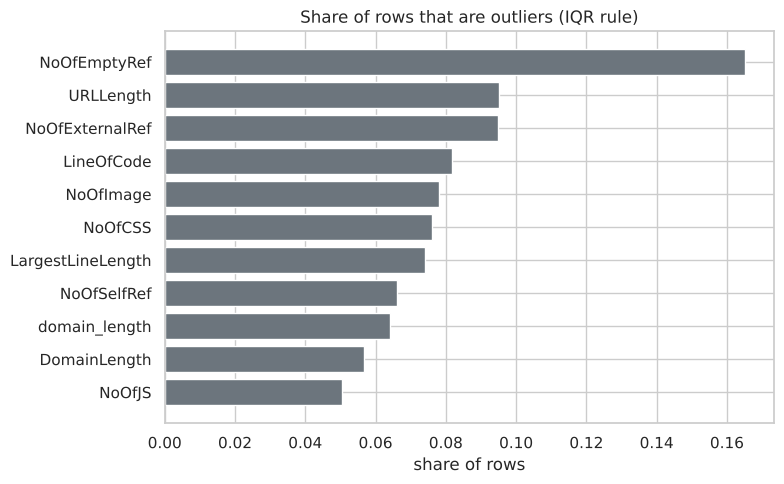

NoOfJS                5.0%
DomainLength          5.7%
domain_length         6.4%
NoOfSelfRef           6.6%
LargestLineLength     7.4%
NoOfCSS               7.6%
NoOfImage             7.8%
LineOfCode            8.2%
NoOfExternalRef       9.5%
URLLength             9.5%
NoOfEmptyRef         16.5%
dtype: str

In [56]:
def iqr_share(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean()

out_cols = ["URLLength", "DomainLength", "domain_length", "LineOfCode", "LargestLineLength", "NoOfImage", "NoOfCSS",
            "NoOfJS", "NoOfSelfRef", "NoOfExternalRef", "NoOfEmptyRef"]
outliers = pd.Series({c: iqr_share(clean[c]) for c in out_cols}).sort_values()
plt.figure(figsize=(8, 5))
plt.barh(outliers.index, outliers.values, color="#6c757d")
plt.title("Share of rows that are outliers (IQR rule)"); plt.xlabel("share of rows")
save("outlier_share")
outliers.map("{:.1%}".format)

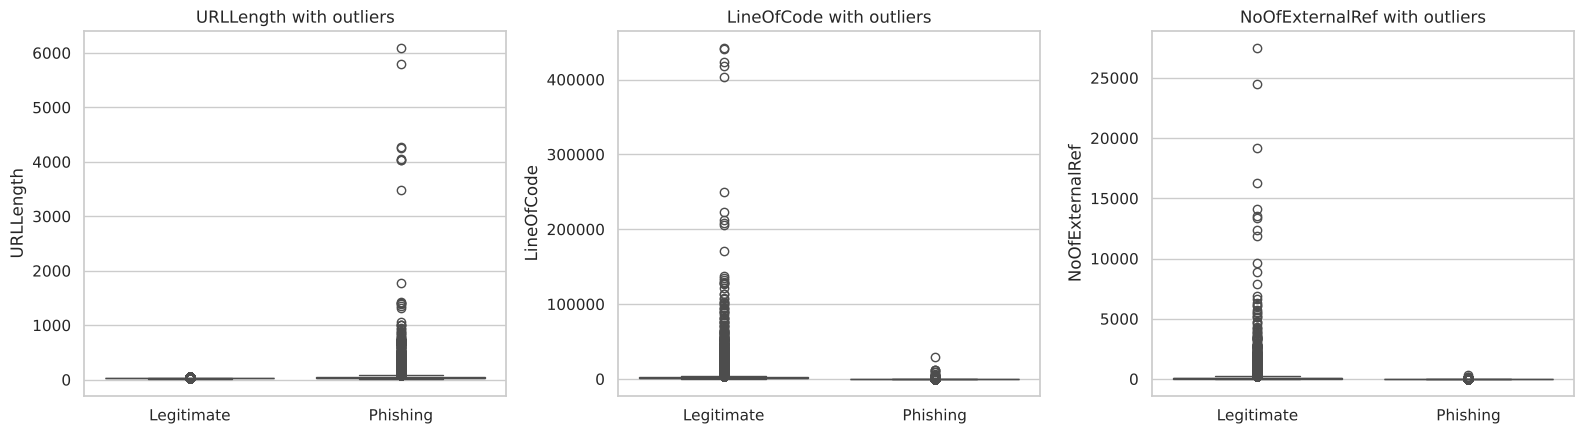

In [57]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, c in zip(axes, ["URLLength", "LineOfCode", "NoOfExternalRef"]):
    sns.boxplot(data=clean, x="label_name", y=c, order=ORDER, palette=PAL, ax=ax)
    ax.set_title(f"{c} with outliers"); ax.set_xlabel("")
save("box_with_outliers")

In [58]:
print("Longest URL:", clean["URLLength"].max(), "characters")
print("Largest page:", f"{clean['LineOfCode'].max():,}", "lines of code")
clean.nlargest(5, "URLLength")[["URL", "URLLength", "label_name"]]

Longest URL: 6097 characters
Largest page: 442,666 lines of code


,URL,URLLength,label_name
102859,https://xwebhostapp.github.io/freehost//#eyj2z...,6097,Phishing
9650,https://b4e921f0.sso-mailsrvr-4344e5teed.pages...,5794,Phishing
150704,https://bodhicardstech.com/beta/wx%20qz%20xx%2...,4274,Phishing
145238,https://inspirationalatmospheres.com/qxzrrr%20...,4246,Phishing
152564,https://bodhicardstech.com/beta/wx%20qz%20xx%2...,4054,Phishing


These outliers are real (really long phishing links, really big real pages), not mistakes. they weren'y deleted (probaly were hidden in plots because i used logs)

## 9. Insights summary

**Patterns I found**
- The data is balanced: about 57% legitimate and 43% phishing.
- Phishing pages are tiny in size. The median phishing page has 12 lines of code.
- Real sites have higher trust_score. The median trust_score is 5 for real sites and 1 for phishing.
- Phishing domains are a bit longer (median 20 characters vs 15, without www.).
- Cheap endings are usually all phishing: .cf, .top, .ml, .site, .ga, .link are 99–100% phishing,
  and .dev, .xyz, .app are around 98%.

**Relationships**
- Page size & phishing: the smaller the page, the more likely it's phishing. 
- Trust score & phishing: the clearest relationship of all (correlation −0.85). Pages with 0–1 signals are ~99% phishing, and pages with 6–7 are ~0%.
- Links on the page & phishing: fewer links to itself (NoOfSelfRef) and to other sites (NoOfExternalRef)
  means more phishing. Real sites are full of menus and links.
- Page size & number of links/images/JS: these all grow together (big pages have everything), which is why
  they all point the same way.
- TLD & phishing: cheap or free endings are mostly phishing. .com, .org and country endings are mostly legitimate.
- Forms & money words: I expected phishing pages to have more password fields and "bank/pay" words, but
  it's the opposite, maybe because many phishing pages were already dead or empty when the data was collected.
- Almost-duplicate columns: DomainLength & domain_length, URLLength & NoOfLettersInURL, and
  DomainTitleMatchScore & URLTitleMatchScore carry the same information.

**Outliers**
- Lots of columns have 5–16% outliers. There are a 6,097-character phishing link and a page with
  442,666 lines of code. 

**Leakage **
- Every real link is https://www.something.com with nothing after it. A one-line rule based on that already
  gets 99.7%, and URLSimilarityIndex alone gets 99.7%.
- I found 21 original columns that leak because of this. They're either the same for every legitimate URL,
  or measured on the full link. Model B leaves them out and uses clean domain features instead.

**Key takeaways**
- Phishing sites are small, quick, throw-away pages with few trust signals and cheap endings.
- Some columns score well only because of how the data was collected, so checking for that
  before trusting a 100% score is essential.

## 10. Model
Two things happen here:
1. **Model A vs Model B** on the full dataset, to show how much the leaky columns inflate the score.
2. **The link checker** used in the Streamlit app. It only sees what a person can paste (the website name and
   its ending), so it's trained on that alone.

The test set is made of websites the model has **never seen**: every website is either fully in train or fully
in test, so the model can't just memorise names.

In [59]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (recall_score, precision_score, f1_score, accuracy_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay)

df = pd.read_csv("clean_features.csv")   # read the saved file again, so this section can run on its own
y = df["is_phishing"]

def registered_domain(d):
    parts = d.split(".")
    if len(parts) >= 3 and len(parts[-1]) == 2 and parts[-2] in {"co", "com", "org", "net", "ac", "gov", "edu"}:
        return ".".join(parts[-3:])
    return ".".join(parts[-2:])

df["website"] = df["Domain"].str.lower().str.replace(r"^www\.", "", regex=True).map(registered_domain)

# 80/20 split, stratified, and grouped by website
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(sgkf.split(df, y, groups=df["website"]))
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
print("train:", len(train_idx), " test:", len(test_idx))
print("test websites also in train:", df["website"].iloc[test_idx].isin(set(df["website"].iloc[train_idx])).mean())

def scores(y_true, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {"recall (phishing)": recall_score(y_true, pred), "precision (phishing)": precision_score(y_true, pred),
            "F1": f1_score(y_true, pred), "accuracy": accuracy_score(y_true, pred),
            "ROC-AUC": roc_auc_score(y_true, prob), "missed phishing": int(fn), "false alarms": int(fp)}

train: 188295  test: 47075


test websites also in train: 0.0


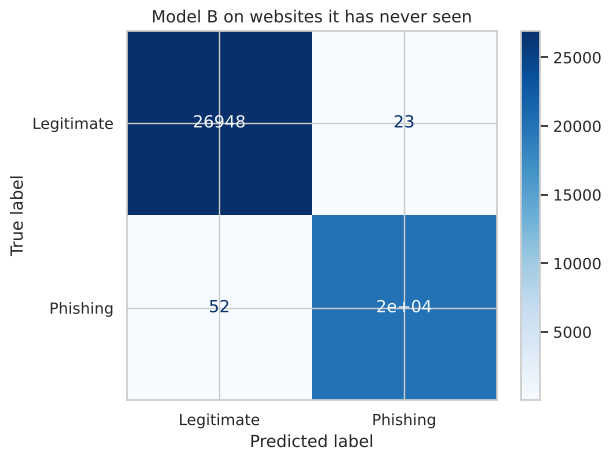

,recall (phishing),precision (phishing),F1,accuracy,ROC-AUC,missed phishing,false alarms
Model A (with leaks),1.0000,1.0000,1.0000,1.0000,1.0,0.0,0.0
Model B (no leaks),0.9974,0.9989,0.9981,0.9984,1.0,52.0,23.0


In [60]:
LEAKY = ["URLSimilarityIndex", "IsHTTPS", "IsDomainIP", "HasObfuscation", "NoOfObfuscatedChar", "ObfuscationRatio",
         "NoOfEqualsInURL", "NoOfQMarkInURL", "NoOfAmpersandInURL", "URLLength", "NoOfLettersInURL",
         "LetterRatioInURL", "NoOfDigitsInURL", "DigitRatioInURL", "NoOfOtherSpecialCharsInURL",
         "SpecialCharRatioInURL", "CharContinuationRate", "URLCharProb", "URLTitleMatchScore", "DomainLength",
         "NoOfSubDomain"]
GOOD = ["TLDLegitimateProb", "TLDLength", "LineOfCode", "LargestLineLength", "HasTitle", "DomainTitleMatchScore",
        "HasFavicon", "Robots", "IsResponsive", "NoOfURLRedirect", "NoOfSelfRedirect", "HasDescription", "NoOfPopup",
        "NoOfiFrame", "HasExternalFormSubmit", "HasSocialNet", "HasSubmitButton", "HasHiddenFields",
        "HasPasswordField", "Bank", "Pay", "Crypto", "HasCopyrightInfo", "NoOfImage", "NoOfCSS", "NoOfJS",
        "NoOfSelfRef", "NoOfEmptyRef", "NoOfExternalRef"]
FEATURES_A = GOOD + LEAKY                                                                 # everything
FEATURES_B = GOOD + ["domain_length", "domain_digits", "domain_hyphens", "domain_dots"]   # no leaks

results = {}
for name, feats in [("Model A (with leaks)", FEATURES_A), ("Model B (no leaks)", FEATURES_B)]:
    model = HistGradientBoostingClassifier(max_leaf_nodes=63, learning_rate=0.1, random_state=42)
    model.fit(df.iloc[train_idx][feats], y_train)
    prob = model.predict_proba(df.iloc[test_idx][feats])[:, 1]
    results[name] = scores(y_test, prob)
    if name.startswith("Model B"):
        prob_b = prob

ConfusionMatrixDisplay.from_predictions(y_test, (prob_b >= 0.5).astype(int),
                                        display_labels=["Legitimate", "Phishing"], cmap="Blues")
plt.title("Model B on websites it has never seen")
plt.show()
pd.DataFrame(results).T.round(4)

### The link checker for the app
Model B is great, but it needs the page itself and it's information. Someone checking a suspicious
SMS only has the link, so the app uses a smaller model that reads just the website name and its ending.

It reads two things:
- the letter patterns of the name (TF-IDF of short chunks of characters)
- 12 numbers about the name: its length, digits, hyphens and share of vowels, the ending and how common it is
  among real sites, and whether it sits on a free website builder. Five of them are new and aim at the kind of
  links the first version missed:
  - how random the name looks: how mixed its characters are, its longest run of consonants, and how
    often it switches between digits and letters, like `uyr434dg`
  - how close it is to a famous brand: a brand inside the name (`paypal-secure`) or a name that imitates one
    (`paypa1`, `amaz0n`, `facebok`)

Then three steps, all on the training websites. The test websites are only used once, at the very end.
1. Tuning. I tried a few settings on a validation part of the training data, split by website again:
  the model is held back from trusting single patterns and the longest letter chunk it reads.
2. A logistic regression's score isn't automatically a real chance. Every training link gets a
   score from a model that never saw its website (out-of-fold scores), and an isotonic regression learns from
   those what share of links really were phishing at each score.
3. Threshold. The warning starts at the lowest score where 10% or fewer of the real sites get a false alarm.

Before trusting the score, the app also checks two lists: the 10,000 most visited websites
(models/popular_domains_top10k.txt, from [Tranco list](https://tranco-list.eu) )
and a short list of trusted Saudi sites in link_checker.py (almost everything ending in .gov.sa or .edu.sa, plus the
main banks). Phishing links copy famous names, so the model may flag some real sites.

In [61]:
from pathlib import Path
import joblib
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import brier_score_loss
from link_checker import link_frame, LINK_FEATURES

tld_probs = df.groupby("TLD")["TLDLegitimateProb"].first().to_dict()   # one value per ending
X_link = link_frame(df["URL"], tld_probs)
X_train_link, X_test_link = X_link.iloc[train_idx], X_link.iloc[test_idx]
groups_train = df["website"].iloc[train_idx]

# the five new numbers, average per link
print(X_link[LINK_FEATURES[7:]].groupby(df["label_name"]).mean().round(3).T, "\n")


def make_link_model(C=1, longest_chunk=5, numbers=LINK_FEATURES):
    # everything is in one pipeline, so TF-IDF and the scaler only ever learn from the rows they're fitted on
    return make_pipeline(
        ColumnTransformer([
            ("letters", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, longest_chunk), min_df=3,
                                        sublinear_tf=True), "text"),
            ("numbers", StandardScaler(), numbers),
        ]),
        LogisticRegression(C=C, max_iter=3000),
    )


def recall_at_10(y_true, prob):
    """Share of phishing caught when the cut-off lets at most 10% of the real sites through as false alarms."""
    cut = np.quantile(prob[y_true == 0], 0.90)
    return (prob[y_true == 1] > cut).mean()


# split the training websites again: fit on one part, compare the settings on the other
folds = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=1)
fit_rel, val_rel = next(folds.split(X_train_link, y_train, groups=groups_train))
y_fit, y_val = y_train.iloc[fit_rel], y_train.iloc[val_rel].to_numpy()

def try_settings(**settings):
    m = make_link_model(**settings).fit(X_train_link.iloc[fit_rel], y_fit)
    p = m.predict_proba(X_train_link.iloc[val_rel])[:, 1]
    return {"AUC": roc_auc_score(y_val, p), "recall at 10% false alarms": recall_at_10(y_val, p)}

# first: do the five new numbers help? same settings, with and without them
feature_check = pd.DataFrame({"first version (7 numbers)": try_settings(numbers=LINK_FEATURES[:7]),
                              "now (12 numbers)": try_settings()}).T
print(feature_check.round(4), "\n")

# then a few settings, picked by how much phishing they catch at 10% false alarms
tuning = pd.DataFrame([{"C": C, "longest chunk": longest, **try_settings(C=C, longest_chunk=longest)}
                       for C in [0.5, 1, 2] for longest in [5, 6]])
tuning = tuning.sort_values("recall at 10% false alarms", ascending=False)
BEST_C, BEST_CHUNK = float(tuning.iloc[0]["C"]), int(tuning.iloc[0]["longest chunk"])
print(f"best: C={BEST_C}, chunks of 2 to {BEST_CHUNK} characters")
tuning.round(4)

label_name           Legitimate  Phishing
name_entropy              2.788     2.753
name_consonant_run        2.382     2.482
name_digit_switches       0.032     0.442
brand_in_name             0.001     0.020
brand_lookalike           0.000     0.004 



                              AUC  recall at 10% false alarms
first version (7 numbers)  0.8952                      0.7425
now (12 numbers)           0.8959                      0.7448 



best: C=1.0, chunks of 2 to 5 characters


,C,longest chunk,AUC,recall at 10% false alarms
2,1.0,5,0.8959,0.7448
3,1.0,6,0.8950,0.7437
4,2.0,5,0.8933,0.7423
5,2.0,6,0.8917,0.7416
1,0.5,6,0.8957,0.7400
0,0.5,5,0.8961,0.7394


In [ ]:
# out-of-fold scores: every training link is scored by a model that never saw its website
oof = cross_val_predict(make_link_model(BEST_C, BEST_CHUNK), X_train_link, y_train, groups=groups_train,
                        cv=folds, method="predict_proba")[:, 1]

#calibration: learn what share of links really were phishing at each score
calibrator = IsotonicRegression(out_of_bounds="clip").fit(oof, y_train)
oof_calibrated = calibrator.predict(oof)

# threshold: catch as much phishing as possible while 10% or fewer of the real sites get a false alarm
rows = []
for t in np.arange(0.2, 0.61, 0.05):
    s = scores(y_train, oof_calibrated, t)
    rows.append({"threshold": round(t, 2), "recall": s["recall (phishing)"], "precision": s["precision (phishing)"],
                 "false alarm rate": s["false alarms"] / (y_train == 0).sum()})
thr_table = pd.DataFrame(rows)
print(thr_table.round(3))
THRESHOLD = float(thr_table.loc[thr_table["false alarm rate"] <= 0.10, "threshold"].min())
print("chosen threshold:", THRESHOLD)

# 4. the final model learns from all the training links, then the test websites are used once
link_pipeline = make_link_model(BEST_C, BEST_CHUNK).fit(X_train_link, y_train)
raw_prob = link_pipeline.predict_proba(X_test_link)[:, 1]
link_prob = calibrator.predict(raw_prob)
link_scores = scores(y_test, link_prob, THRESHOLD)
pd.DataFrame({"raw score, threshold 0.5": scores(y_test, raw_prob, 0.5),
              f"calibrated, threshold {THRESHOLD}": link_scores}).T.round(4)

   threshold  recall  precision  false alarm rate
0       0.20   0.895      0.643             0.371
1       0.25   0.848      0.718             0.248
2       0.30   0.838      0.734             0.226
3       0.35   0.776      0.814             0.132
4       0.40   0.772      0.820             0.126
5       0.45   0.772      0.820             0.126
6       0.50   0.709      0.885             0.069
7       0.55   0.709      0.885             0.069
8       0.60   0.709      0.885             0.069
chosen threshold: 0.5


,recall (phishing),precision (phishing),F1,accuracy,ROC-AUC,missed phishing,false alarms
"raw score, threshold 0.5",0.6886,0.9298,0.7912,0.8448,0.9024,6261.0,1045.0
"calibrated, threshold 0.5",0.7331,0.8869,0.8027,0.8461,0.9022,5365.0,1880.0


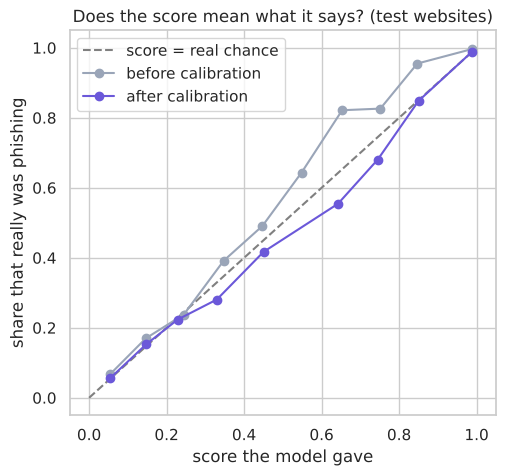

Brier score (lower is better): 0.1145 before, 0.1134 after


Saved models/link_model.joblib


In [63]:
# does a score of 40% really mean 40%? group the test links by score and see how many were phishing
def reliability(prob, n_bins=10):
    bins = pd.cut(prob, np.linspace(0, 1, n_bins + 1), include_lowest=True)
    return (pd.DataFrame({"score": prob, "phishing": y_test.to_numpy()})
            .groupby(bins, observed=True)
            .agg(links=("phishing", "size"), average_score=("score", "mean"), really_phishing=("phishing", "mean")))

before, after = reliability(raw_prob), reliability(link_prob)
plt.figure(figsize=(5.5, 5))
plt.plot([0, 1], [0, 1], "--", color="grey", label="score = real chance")
plt.plot(before["average_score"], before["really_phishing"], "o-", color="#9aa5b8", label="before calibration")
plt.plot(after["average_score"], after["really_phishing"], "o-", color="#6b58d9", label="after calibration")
plt.xlabel("score the model gave")
plt.ylabel("share that really was phishing")
plt.title("Does the score mean what it says? (test websites)")
plt.legend()
plt.show()
print(f"Brier score (lower is better): {brier_score_loss(y_test, raw_prob):.4f} before, "
      f"{brier_score_loss(y_test, link_prob):.4f} after")

# save what the app needs, including a small version of this check for the app to show
check = reliability(link_prob, 5)
check = [{"score": f"{iv.left:.0%} to {iv.right:.0%}".replace("-0%", "0%"), "links": int(r["links"]),
          "average score": float(r["average_score"]), "really phishing": float(r["really_phishing"])}
         for iv, r in check.iterrows()]
# the results the dashboard shows in its Model results section
tn, fp, fn, tp = confusion_matrix(y_test, (link_prob >= THRESHOLD).astype(int)).ravel()
report = {
    "full_models": results,
    "columns_used": {"Model A (with leaks)": len(FEATURES_A), "Model B (no leaks)": len(FEATURES_B)},
    "confusion": {"caught": int(tp), "missed": int(fn), "false alarms": int(fp), "passed": int(tn)},
    "calibration_curve": {"before": before.to_dict("records"), "after": after.to_dict("records")},
    "tuning": tuning.to_dict("records"),
    "feature_check": feature_check.rename_axis("version").reset_index().to_dict("records"),
    "n_test": len(test_idx),
}
Path("models").mkdir(exist_ok=True)
joblib.dump({"pipeline": link_pipeline, "calibrator": calibrator, "threshold": THRESHOLD, "tld_probs": tld_probs,
             "test_scores": link_scores, "n_train": len(train_idx), "calibration_check": check, "report": report},
            "models/link_model.joblib")
print("Saved models/link_model.joblib")

**Result:** on websites it has never seen, the link checker catches about 73% of phishing links, and 89% of
its warnings really are phishing. It's right 84.6% of the time overall and gives a false alarm on 7% of real sites.

The model is about as good as it was, but its score now means something. It is
still much weaker than Model B, because it only sees the name and not the page. That's why the app doesn't
trust the score alone: it also uses the red-flag rules, the popular-site list and the trusted Saudi list.

## 11. Final summary 

### What I learned
- A perfect score may mean something is wrong. Model A got 100%, and the reason was the data itself: every real link is a bare https://www. homepage. Checking each column on its own is what showed the leak.
- Split the data matters as much as the model. If the same website can be in both train and test,
  the model just remembers names. 
- Phishing pages are usually small, quick and bare: few lines of code, almost no images or scripts, and almost none
  of the 7 trust signals. 

### Limitations
- The real links in this dataset aren't realistic. They're all homepages, collected differently from the
  phishing links, so anything learned from the full link mostly describes how the data was built.
- There are almost no Saudi sites in the data
- Many phishing pages were already dead or half-built when they were collected, which is why they have fewer
  password boxes than real sites. 
- The link checker only sees the name. It can't spot a real website that was hacked.
- The popular-site list and the trusted Saudi list are fixed snapshots and would need updating (not a permanent fix).

### Recommendations for future analysis
- Collect real links that aren't just homepages, gathered the same way as the phishing links.
- Add Saudi and Arabic data.
- Add facts that need a lookup: how old the domain is, its HTTPS certificate, and whether it's on a live
  phishing list.
- Try a feature for how much of a name is made of real words, using a dictionary.
- Test on a realistic mix, like 1 phishing link in 100, to see how many false alarms a real person would get,